<h1><font color='blue'>Sistemas de Recomendação - Recomendação colaborativa</font></h1>


## Visão geral

Este projeto apresenta experimentos práticos com **sistemas de recomendação colaborativa**, explorando como avaliações históricas de usuários podem ser utilizadas para identificar preferências, estimar notas e gerar rankings personalizados de filmes.

O notebook explora técnicas com pequenas matrizes de avaliações para experimentos com dados de filmes e avaliações, implementando abordagens baseadas em vizinhança, fatoração de matrizes e ranking. Também compara modelos com métricas de erro de predição e métricas de qualidade do ranking.

O trabalho foi desenvolvido no contexto acadêmico da Pós-Graduação em Inteligência Artificial e Aprendizado de Máquina da PUC Minas com foco no entendimento dos conceitos e na implementação de protótipos em Python.

## Objetivos

- Compreender os fundamentos da recomendação colaborativa e a diferença entre prever notas (*rating prediction*) e ordenar itens (*ranking*).
- Explorar as abordagens **User-User** e **Item-Item**.
- Preparar dados de avaliações no formato usuário–item–nota e construir matrizes de interação.
- Treinar modelos colaborativos baseados em vizinhança e em fatores latentes.
- Gerar recomendações personalizadas, evitando recomendar itens já avaliados pelo usuário.
- Comparar modelos utilizando métricas adequadas à tarefa.

## Dados e preparação

O notebook utiliza dois conjuntos de dados:

- **Avaliações coletadas por formulário de alguns usuários:** avaliações de um conjunto de filmes são convertidas para o formato `user`, `item` e `rating`. Respostas ausentes ou notas iguais a zero são descartadas nessa preparação.
- **Dados de filmes e avaliações:** A prática utiliza exemplos de recomendação de filmes com o conjunto de dados **MovieLens**..

As principais etapas de preparação incluem:

- Conversão das avaliações para formato longo e padronização dos identificadores de usuário e filme.
- Construção de matrizes usuário × item, nas quais valores ausentes representam interações não observadas.
- Conversão dos registros para os formatos exigidos pelas bibliotecas Cornac e Surprise.
- Separação de conjuntos de treino e teste para avaliação dos modelos.


## Técnicas implementadas

* Recomendação baseada em vizinhança
* Modelos colaborativos para previsão de notas (*rating*)
* Modelos colaborativos para ranking
* Geração de recomendações
* Perfil de usuário por gêneros


# Conceitos Fundamentais

In [1]:
from IPython.display import Image

## Recomendação Colaborativa

Recomendações definidas de acordo com os pares ou relacionamentos do usuário.
* Explora a “wisdom of the crowd”
* Considera a similaridade entre usuários e entre itens
* Utiliza os itens avaliados por usuários para gerar as recomendações

## Estratégias de Filtragem Colaborativa

<font color='blue'>**Memory-based**</font>
* Usa a similaridade (vizinhança) dos dados para estimar as avaliações (geralmente, a matriz é mantida em memória)
* User-User: explora a similaridade entre os usuários
* Item-Item: explora a similaridade entre os itens

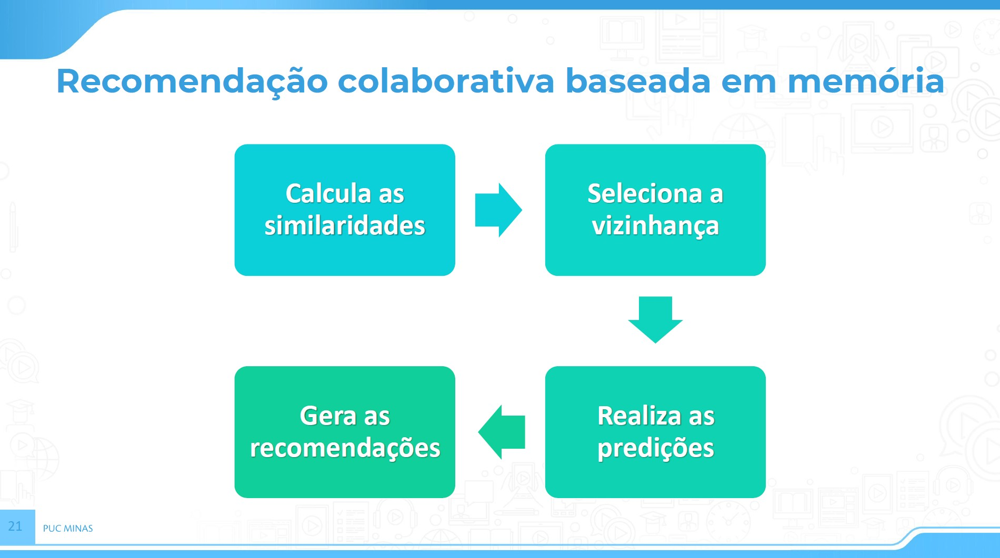

In [2]:
Image('./imagens/aula_05_015.jpg', width=800)

<font color='blue'>**Model- based**</font>
* A recomendação colaborativa baseada em modelo utiliza técnicas de aprendizado de máquina e estatística para aprender um modelo preditivo a partir do histórico de interações entre usuários e itens
* Geralmente, usa modelos de grafos, aprendizado profundo ou de fatoração de matrizes (SVD, NMF etc.)
* Diferente da abordagem baseada em memória, os dados não são usados diretamente para recomendar, mas para treinar um modelo que generaliza padrões latentes

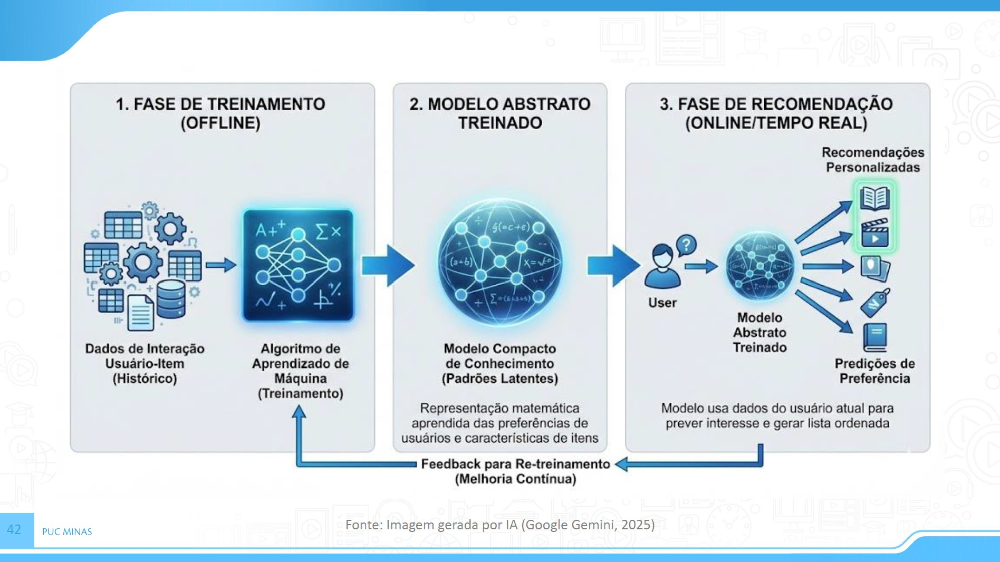

In [3]:
Image('./imagens/aula_05_017.jpg', width=1000)

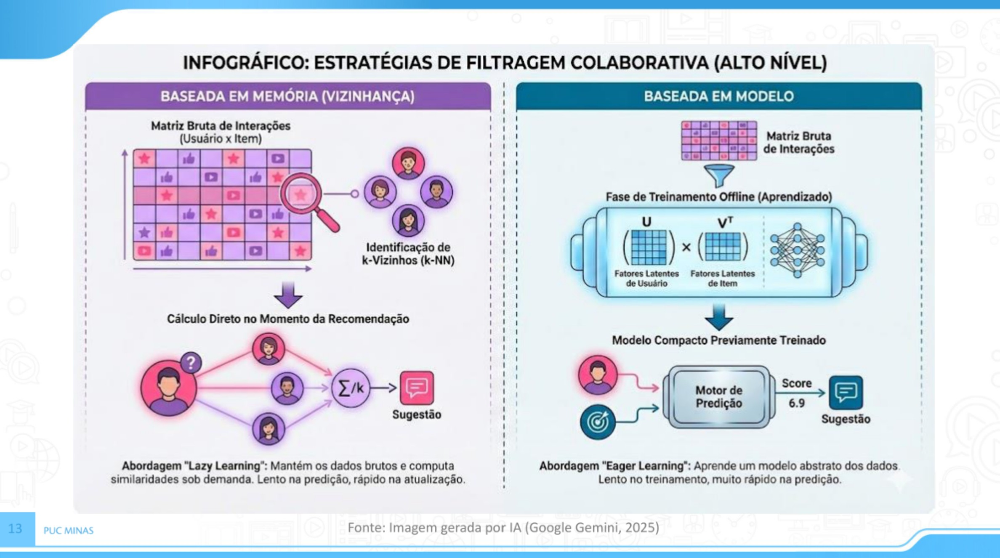

In [4]:
Image('./imagens/aula_05_005.jpg', width=1000)

## Tipos
* Não Personalizada
    * Poderia considerar a avaliação média dos itens como medida para os itens não avaliados
* Personalizada
    *  Usuários avaliam os itens de forma implícita ou explícita
    *  Usuários que tiveram avaliações (gostos) similares no passado “deverão” ter avaliações similares no futuro

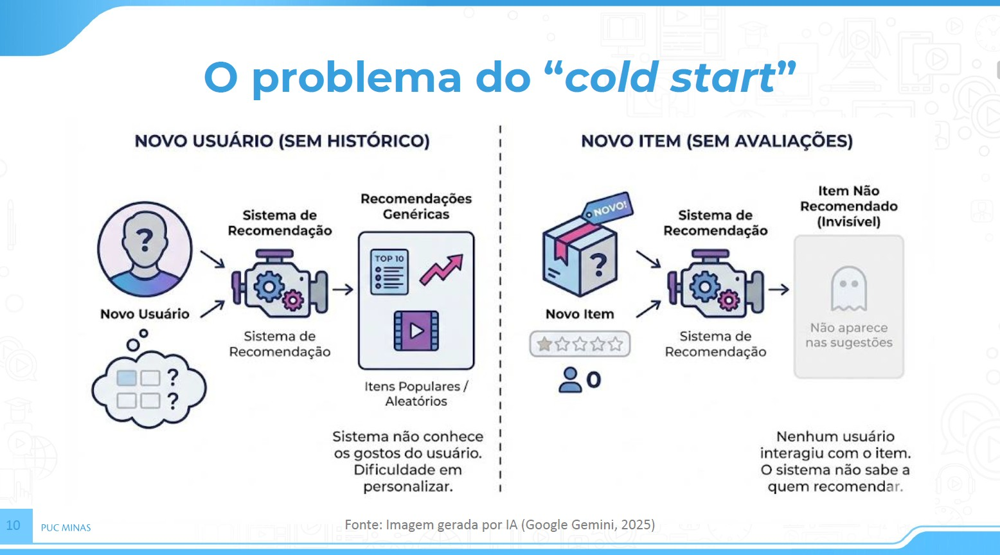

In [5]:
Image('./imagens/aula_05_001.jpg', width=1000)

## <font color = 'red'>**“cold start”**</font>
* A recomendação colaborativa necessita de avaliações de itens e usuários para se computar as similaridades
    * Sem dados históricos, não há colaboração.
* O problema do “cold start”
    * O cold start ocorre quando o sistema não possui dados suficientes de interação para gerar recomendações confiáveis.

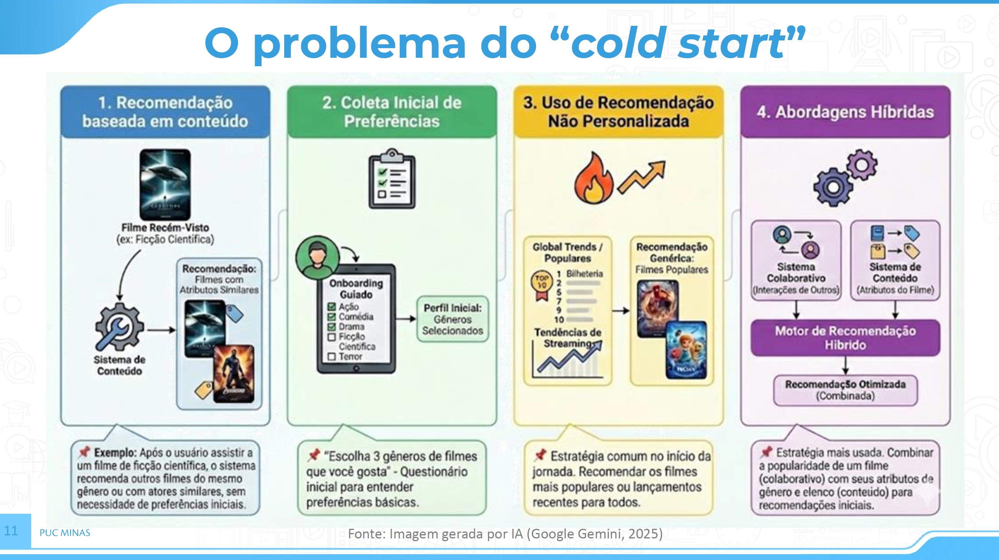

In [6]:
Image('./imagens/aula_05_003.jpg', width = 1000)

## Métodos de rating vs ranking

Na recomendação colaborativa, é possível usar modelos com dois objetivos diferentes

* Métodos baseados em rating
    * Prever quanto o usuário vai gostar de um item
* Métodos baseados em ranking
    *  Ordenar itens do mais para o menos relevante

A diferença central está no objetivo do modelo, não apenas no formato da saída.

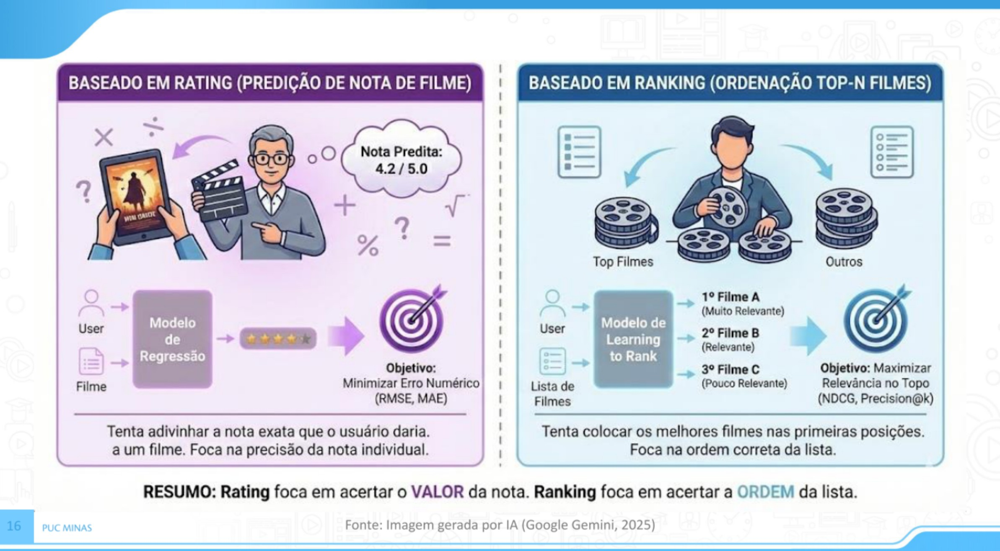

In [7]:
Image('./imagens/aula_05_004.jpg', width=1000)

<font color='blue'>**Baseados em rating**</font>
* O objetivo é prever explicitamente a nota numérica que um usuário daria a um item
* A saída é a avaliação do usuário para um item
* Algoritmos
    * User-Based CF
    * Item-Based
    * Matrix Factorization (SVD, ALS)

<font color='blue'>**Baseados em ranking**</font>
*  Não tentam prever uma nota explícita, mas sim ordenar os itens de acordo com a probabilidade de interesse do usuário
*  A saída deve indicar a ordem dos itens para um usuário
*  Algoritmos
    *  BPR (Bayesian Personalized Ranking)
    *  LambdaRank
    *  Modelos baseados em pares

## Preparação do ambiente

In [8]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import Image

from sklearn.metrics.pairwise import cosine_similarity

import surprise
from surprise import (
    Dataset,
    Reader,
    KNNBasic,
    KNNWithMeans,
    KNNBaseline,
    SVD,
    SVDpp,
    NMF,
    BaselineOnly
)
from surprise.model_selection import train_test_split
from surprise import accuracy

import cornac
from cornac.data import Dataset
from cornac.eval_methods import RatioSplit
from cornac.models import UserKNN, ItemKNN, NMF, MF, BPR, PMF, SVD, LightGCN, WBPR
from cornac.metrics import MAE, RMSE, Precision, Recall, NDCG, MAP

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

# Entendendo a recomendação colaborativa

## Formulários

Alguns usuários avaliaram alguns filmes dentro de uma lista de filmes fechada de um formulário. 

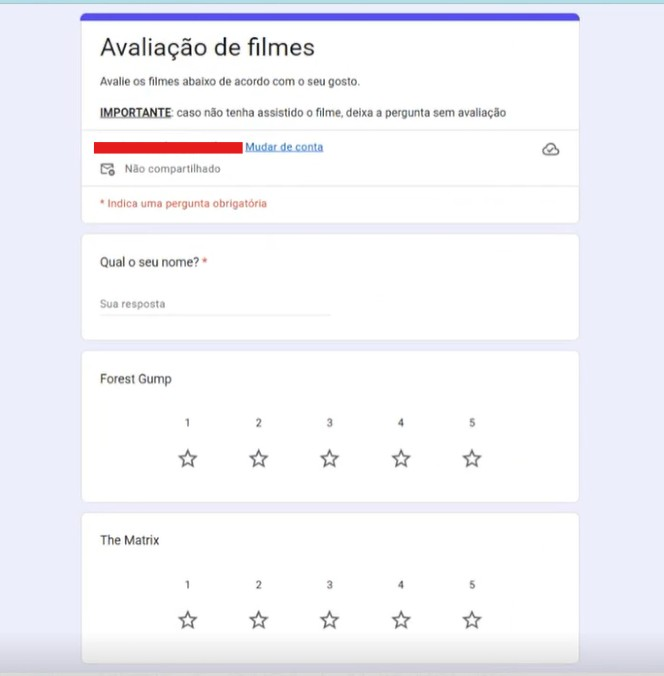

In [9]:
Image('./imagens/aula_05_002.jpg')

In [10]:
respostas = pd.read_csv('./datasets/formularios_alunos.csv')

In [11]:
respostas['Jurassic Park'] = respostas['Jurassic Park'].astype(float)
respostas.iloc[:,2:] = respostas.iloc[:,2:].astype(float)

In [12]:
respostas.shape

(11, 22)

In [13]:
print("Quantidade de respostas:", len(respostas))
display(respostas.head())

Quantidade de respostas: 11


,Carimbo de data/hora,Qual o seu nome?,Forest Gump,The Matrix,Jurassic Park,Toy Story,Titanic,O Rei Leão,Pulp Fiction,Um sonho de liberdade,O silêncio dos inocentes,Clube de Luta,Senhor dos anéis: o retorno do rei,De volta para o futuro,Caçadores da arca perdida,O exterminador do futuro 2,Star wars: episódio IV - Uma nova esperança,Star wars: episódio V - O império contra-ataca,Star wars: episódio VI - O retorno de Jedi,O Senhor dos Anéis: A Sociedade do Anel,A Origem,Batman: O Cavaleiro das Trevas
0,02/09/2026 19:48:23,Humberto,4.0,3.0,2.0,2.0,NaN,NaN,3.0,5.0,NaN,NaN,4.0,5.0,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN
1,02/09/2026 19:49:13,PedroLucas,NaN,5.0,4.0,4.0,3.0,4.0,NaN,NaN,5.0,5.0,5.0,NaN,NaN,4.0,NaN,NaN,NaN,5.0,NaN,5.0
2,02/09/2026 19:50:02,GilmarJusto,5.0,NaN,4.0,NaN,4.0,4.0,4.0,5.0,5.0,5.0,NaN,4.0,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN
3,02/09/2026 19:50:06,Gabriel Oliveira,4.0,NaN,3.0,5.0,3.0,5.0,NaN,5.0,NaN,NaN,3.0,5.0,4.0,5.0,2.0,2.0,2.0,NaN,NaN,5.0
4,02/09/2026 19:50:10,Bruno Braga,NaN,4.0,3.0,3.0,2.0,5.0,NaN,NaN,5.0,NaN,5.0,4.0,3.0,4.0,5.0,5.0,5.0,5.0,4.0,5.0


## Lista de filmes utilizados no formulário

In [14]:
filmes_forms = {
    "Forest Gump": 356,
    "The Matrix": 2571,
    "Jurassic Park": 480,
    "Toy Story": 1,
    "Titanic": 1721,
    "O Rei Leão": 364,
    "Pulp Fiction": 296,
    "Um sonho de liberdade": 318,
    "O silêncio dos inocentes": 593,
    "Clube de Luta": 2959,
    "Senhor dos anéis: o retorno do rei": 7153,
    "De volta para o futuro": 1270,
    "Caçadores da arca perdida": 1198,
    "O exterminador do futuro 2": 589,
    "Star wars: episódio IV - Uma nova esperança": 260,
    "Star wars: episódio V - O império contra-ataca": 1196,
    "Star wars: episódio VI - O retorno de Jedi": 1210,
    "O Senhor dos Anéis: A Sociedade do Anel": 4993,
    "A Origem": 79132,
    "Batman: O Cavaleiro das Trevas": 58559
}

pd.DataFrame(
    list(filmes_forms.items()),
    columns=["filme", "movieId"]
)

,filme,movieId
0,Forest Gump,356
1,The Matrix,2571
2,Jurassic Park,480
3,Toy Story,1
4,Titanic,1721
5,O Rei Leão,364
6,Pulp Fiction,296
7,Um sonho de liberdade,318
8,O silêncio dos inocentes,593
9,Clube de Luta,2959


**Abordagem colaborativa**

O universo de filmes a ser recomendados são os mesmos 20 filmes sugeridos no formulários.

Somente as notas atribuidas dos usuários serão utilizadas para treinar o modelo. Nenhuma informação adicional sobre os filmes, tais como sinopse, nome persuativo, banners e etc ou dados pessoais dos usuários são utilizada no treinamento.

Os nomes e identificadores dos filmes tem origem no dataset MovieLens, porém nessa abordagem somente o contexto dos filmes do formulário é utilizado no treinamento e nas sugestões de recomendações.

## Convertendo as respostas para user / item / rating

<font color='blue'>**Processando as respostas dos formulário e adequando ao padrão do dataset do MovieLens.**</font>

In [15]:
COLUNA_ALUNO = "Qual o seu nome?"

avaliacoes_turma = respostas.melt(
    id_vars=[COLUNA_ALUNO],
    value_vars=list(filmes_forms.keys()),
    var_name="filme",
    value_name="rating"
)

avaliacoes_turma["movieId"] = (
    avaliacoes_turma["filme"].map(filmes_forms)
)

avaliacoes_turma["rating"] = pd.to_numeric(
    avaliacoes_turma["rating"],
    errors="coerce"
)

avaliacoes_turma = avaliacoes_turma[
    avaliacoes_turma["rating"] > 0
].copy()

ratings_turma = (
    avaliacoes_turma[
        [COLUNA_ALUNO, "movieId", "rating"]
    ]
    .rename(
        columns={
            COLUNA_ALUNO: "user",
            "movieId": "item"
        }
    )
)

display(ratings_turma.head(10))

,user,item,rating
0,Humberto,356,4.0
2,GilmarJusto,356,5.0
3,Gabriel Oliveira,356,4.0
5,Marcelly,356,4.0
6,Pedro Augusto,356,5.0
7,Carlos Penido,356,5.0
8,Gabriel moscatel,356,4.0
9,Moretto,356,5.0
10,Vitor G,356,5.0
11,Humberto,2571,3.0


<font color='blue'>**Resumo descritivo das avaliações dos alunos.**</font>

In [16]:
print("Alunos:", ratings_turma["user"].nunique())
print("Filmes avaliados:", ratings_turma["item"].nunique())
print("Total de ratings:", len(ratings_turma))

display(
    ratings_turma.groupby("user")
    .size()
    .sort_values(ascending=False)
    .to_frame("quantidade")
)

Alunos: 11
Filmes avaliados: 20
Total de ratings: 169


,quantidade
user,
Carlos Penido,20
Pedro Augusto,20
Marcelly,20
Vitor G,20
Bruno Braga,16
Moretto,16
Gabriel Oliveira,14
Gabriel moscatel,13
PedroLucas,11


## Matriz usuários × filmes

In [17]:
matriz_turma = ratings_turma.pivot(
    index="user",
    columns="item",
    values="rating"
)

display(matriz_turma)

item,1,260,296,318,356,364,480,589,593,1196,1198,1210,1270,1721,2571,2959,4993,7153,58559,79132
user,,,,,,,,,,,,,,,,,,,,
Bruno Braga,3.0,5.0,NaN,NaN,NaN,5.0,3.0,4.0,5.0,5.0,3.0,5.0,4.0,2.0,4.0,NaN,5.0,5.0,5.0,4.0
Carlos Penido,3.0,5.0,1.0,1.0,5.0,1.0,5.0,3.0,2.0,5.0,1.0,5.0,5.0,2.0,5.0,4.0,3.0,4.0,3.0,2.0
Gabriel Oliveira,5.0,2.0,NaN,5.0,4.0,5.0,3.0,5.0,NaN,2.0,4.0,2.0,5.0,3.0,NaN,NaN,NaN,3.0,5.0,NaN
Gabriel moscatel,3.0,NaN,NaN,4.0,4.0,5.0,5.0,3.0,NaN,NaN,NaN,NaN,3.0,NaN,4.0,5.0,5.0,5.0,4.0,4.0
GilmarJusto,NaN,NaN,4.0,5.0,5.0,4.0,4.0,3.0,5.0,NaN,NaN,NaN,4.0,4.0,NaN,5.0,NaN,NaN,NaN,NaN
Humberto,2.0,NaN,3.0,5.0,4.0,NaN,2.0,NaN,NaN,3.0,NaN,NaN,5.0,NaN,3.0,NaN,NaN,4.0,NaN,NaN
Marcelly,5.0,2.0,2.0,3.0,4.0,5.0,5.0,4.0,4.0,2.0,4.0,2.0,5.0,2.0,5.0,3.0,5.0,5.0,3.0,5.0
Moretto,3.0,5.0,NaN,NaN,5.0,2.0,4.0,5.0,3.0,5.0,5.0,5.0,5.0,3.0,5.0,NaN,5.0,5.0,NaN,4.0
Pedro Augusto,3.0,5.0,3.0,5.0,5.0,3.0,4.0,5.0,4.0,5.0,1.0,5.0,4.0,3.0,5.0,5.0,1.0,1.0,5.0,5.0


<font color='blue'>**Heatmap das distribuições das avaliações.**</font>

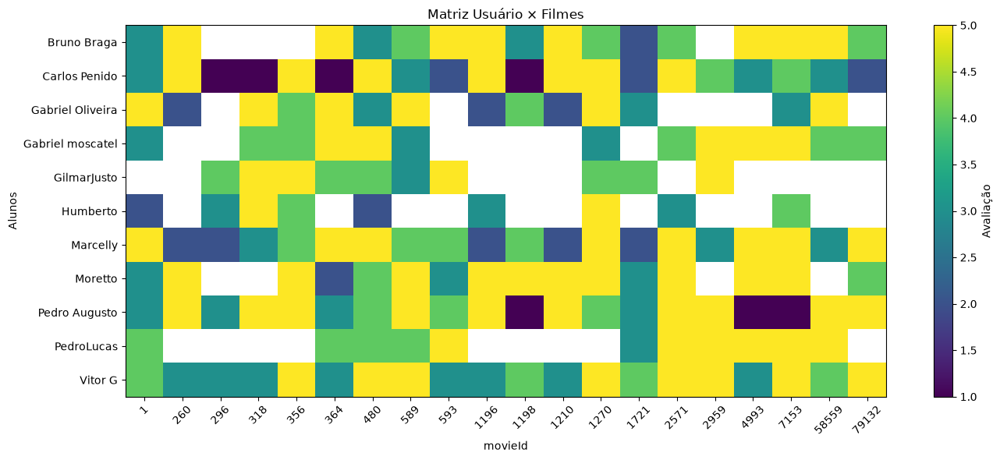

In [18]:
plt.figure(figsize=(14, 6))

plt.imshow(
    matriz_turma,
    aspect="auto"
)

plt.xticks(
    range(len(matriz_turma.columns)),
    matriz_turma.columns,
    rotation=45
)

plt.yticks(
    range(len(matriz_turma.index)),
    matriz_turma.index
)

plt.xlabel("movieId")
plt.ylabel("Alunos")
plt.title("Matriz Usuário × Filmes")
plt.colorbar(label="Avaliação")
plt.tight_layout()
plt.show()

## Preparação de dados

Transformando os dados para a biblioteca `cornac`

In [19]:
dados_cornac_turma = list(
    ratings_turma[
        ["user", "item", "rating"]
    ]
    .itertuples(
        index=False,
        name=None
    )
)

dataset_turma = Dataset.from_uir(dados_cornac_turma)

In [20]:
# Dados originais
print('\nDados originais')
display(
    pd.DataFrame(
        dados_cornac_turma,
        columns=["user", "item", "rating"]
    ).head(5)
)


Dados originais


,user,item,rating
0,Humberto,356,4.0
1,GilmarJusto,356,5.0
2,Gabriel Oliveira,356,4.0
3,Marcelly,356,4.0
4,Pedro Augusto,356,5.0


**Transformação dos textos e itens para índices internos para que o algoritmo funcione.**

In [21]:
# Dados transformados
users, items, ratings_values = dataset_turma.uir_tuple
print('\nDados transformados')
display(
    pd.DataFrame({
        "user_idx": users[:5],
        "item_idx": items[:5],
        "rating": ratings_values[:5]
    })
)


Dados transformados


,user_idx,item_idx,rating
0,0,0,4.0
1,1,0,5.0
2,2,0,4.0
3,3,0,4.0
4,4,0,5.0


* Usuário Humberto -->  user_idx --> 0

* Item 356 --> item_idx --> 0

## Abordagem baseada em *rating*

### Treinando o modelo

Usamos `k=3`: para cada aluno, o algoritmo procura os três usuários mais semelhantes pela estratégia ``user to user``

Para encontra a similaridade foi utilizado o coeficiente de correlação de pearson.

Após o treinamento é gerada uma matriz de correlação.

In [22]:
modelo_turma = UserKNN(
    k=3,
    similarity="pearson",
    name="UserKNN"
)

modelo_turma.fit(
    dataset_turma
)

print("Modelo treinado.")

  0%|          | 0/11 [00:00<?, ?it/s]

Modelo treinado.


### Gerando recomendações

Funcionamento do modelo

* Identificação de usuários similares: a partir da matriz de correlação, são identificados os usuários cujos padrões de avaliação são mais semelhantes aos do usuário que receberá as recomendações de filmes que ainda não assistiu.

* Recomendação de filmes: com base nos filmes avaliados pelos usuários similares, são selecionadas três sugestões de filmes que ainda não foram avaliados pelo usuário.

* Predição de notas: o modelo estima a nota que o usuário provavelmente atribuiria a cada filme recomendado caso o assistisse.

In [23]:
nomes_filmes = {
    movie_id: nome
    for nome, movie_id in filmes_forms.items()
}

def recomendar_para_aluno(
    modelo,
    aluno,
    top_n=3
):
    if aluno not in modelo.train_set.uid_map:
        raise ValueError(
            "Aluno não encontrado no conjunto de treino."
        )

    user_idx = modelo.train_set.uid_map[aluno]

    item_indices, scores = modelo.rank(user_idx)

    vistos = set(
        ratings_turma.loc[
            ratings_turma["user"] == aluno,
            "item"
        ]
    )

    recomendacoes = []

    for idx in item_indices:
        movie_id = modelo.train_set.item_ids[idx]
        if movie_id in vistos:
            continue
        recomendacoes.append(
            {
                "movieId": movie_id,
                "filme": nomes_filmes.get(
                    movie_id,
                    str(movie_id)
                ),
                "score": np.clip(float(scores[idx]), 1.0, 5.0)
            }
        )

        if len(recomendacoes) == top_n:
            break

    return pd.DataFrame(recomendacoes)

In [24]:
alunos = sorted(
    ratings_turma["user"]
    .dropna()
    .unique()
)
alunos

['Bruno Braga',
 'Carlos Penido',
 'Gabriel Oliveira',
 'Gabriel moscatel',
 'GilmarJusto',
 'Humberto',
 'Marcelly',
 'Moretto',
 'Pedro Augusto',
 'PedroLucas',
 'Vitor G']

In [25]:
# recomendação para o usuário Humberto
recomendar_para_aluno(modelo_turma, 'Humberto')

,movieId,filme,score
0,58559,Batman: O Cavaleiro das Trevas,4.249117
1,4993,O Senhor dos Anéis: A Sociedade do Anel,4.123818
2,2959,Clube de Luta,4.108867


**De acordo com o score das predições as sugestões de filmes são ordenadas de forma decrescente.**

* Se o Humberto assistisse "Batman: O Cavaleiro das Trevas" a nota predita da avaliação seria 4.25.

As sugestões foram geradas com base nos demais usuários que preencheram os formulários cujos padrões de avaliação apresentam maior correlação com o perfil de avaliações do Humberto.

A lista apresentou 3 filmes bem avaliados por esses usuários similares, que ainda não foram assistidos por Humberto e que, por esse motivo, foram selecionados para recomendação.

### Recomendações para toda a turma

Os usuários que assitiram e avaliaram todos os 20 filmes não recebem recomendação nesse contexto limitado.

* Carlos Penido	avaliou 20 filmes
* Pedro Augusto avaliou 20 filmes
* Marcelly avaliou 20 filmes

In [26]:
todas_recomendacoes = []

for aluno in alunos:
    recs = recomendar_para_aluno(
        modelo_turma,
        aluno,
        top_n=3
    )

    if len(recs) == 0:
        continue

    recs["Aluno"] = aluno
    todas_recomendacoes.append(recs)

recomendacoes_turma = pd.concat(
    todas_recomendacoes,
    ignore_index=True
)

display(
    recomendacoes_turma[
        ["Aluno", "filme", "score"]
    ]
)

,Aluno,filme,score
0,Bruno Braga,Um sonho de liberdade,4.978027
1,Bruno Braga,Clube de Luta,4.850939
2,Bruno Braga,Forest Gump,4.556883
3,Gabriel Oliveira,A Origem,4.800679
4,Gabriel Oliveira,The Matrix,4.448345
5,Gabriel Oliveira,O Senhor dos Anéis: A Sociedade do Anel,4.296132
6,Gabriel moscatel,O silêncio dos inocentes,4.845771
7,Gabriel moscatel,Star wars: episódio IV - Uma nova esperança,4.590268
8,Gabriel moscatel,Star wars: episódio VI - O retorno de Jedi,4.590268
9,GilmarJusto,Star wars: episódio VI - O retorno de Jedi,5.000000


## Abordagem baseada em *ranking*

### Treinando o modelo

Foi utilizado o algoritmo BPR (Bayesian Personalized Ranking) para rankear os filmes.
* O modelo tenta ordenar os itens de acordo com a relevância ou a preferência estimada para o usuário.

In [27]:
modelo_ranking = BPR(
    k=10,
    max_iter=50,
    learning_rate=0.01,
    lambda_reg=0.01,
    name="BPR"
)

modelo_ranking.fit(
    dataset_turma
)

print("Modelo de ranking treinado.")

Modelo de ranking treinado.


### Gerando recomendações

In [28]:
def recomendar_para_aluno_ranking(
    modelo,
    aluno,
    top_n=3
):
    if aluno not in modelo.train_set.uid_map:
        raise ValueError(
            "Aluno não encontrado no conjunto de treino."
        )

    # Índice interno do usuário no Cornac
    user_idx = modelo.train_set.uid_map[
        aluno
    ]

    # Ranking de todos os itens
    item_indices, scores = modelo.rank(
        user_idx
    )

    # Filmes já avaliados pelo aluno
    vistos = set(
        ratings_turma.loc[
            ratings_turma["user"] == aluno,
            "item"
        ]
    )

    recomendacoes = []

    for idx in item_indices:

        movie_id = modelo.train_set.item_ids[
            idx
        ]

        # Não recomendar itens já avaliados
        if movie_id in vistos:
            continue

        recomendacoes.append(
            {
                "movieId": movie_id,
                "filme": nomes_filmes.get(
                    movie_id,
                    str(movie_id)
                ),
                "ranking_score": float(
                    scores[idx]
                )
            }
        )

        if len(recomendacoes) == top_n:
            break

    return pd.DataFrame(
        recomendacoes
    )

In [29]:
recomendar_para_aluno_ranking(modelo_ranking, 'Humberto')

,movieId,filme,ranking_score
0,589,O exterminador do futuro 2,0.353525
1,364,O Rei Leão,0.337307
2,1721,Titanic,0.134352


O score ordenado dos filmes da lista caso o Humberto assistisses os filmes da das sugestão corresponde 

O score nesse método não tem significado com relação a polaridade do score. 

A polaridade do score apenas serve para colocar os itens em ordem.

### Recomendações para toda a turma

In [30]:
todas_recomendacoes = []

for aluno in alunos:
    recs = recomendar_para_aluno_ranking(
        modelo_ranking,
        aluno,
        top_n=3
    )

    if len(recs) == 0:
        continue

    recs["Aluno"] = aluno
    todas_recomendacoes.append(recs)

recomendacoes_turma = pd.concat(
    todas_recomendacoes,
    ignore_index=True
)

display(
    recomendacoes_turma[
        ["Aluno", "filme", "ranking_score"]
    ]
)

,Aluno,filme,ranking_score
0,Bruno Braga,Forest Gump,0.108582
1,Bruno Braga,Um sonho de liberdade,-0.065228
2,Bruno Braga,Clube de Luta,-0.294955
3,Gabriel Oliveira,The Matrix,0.009378
4,Gabriel Oliveira,O silêncio dos inocentes,-0.042091
5,Gabriel Oliveira,O Senhor dos Anéis: A Sociedade do Anel,-0.155496
6,Gabriel moscatel,Titanic,0.124141
7,Gabriel moscatel,O silêncio dos inocentes,-0.036041
8,Gabriel moscatel,Star wars: episódio V - O império contra-ataca,-0.138985
9,GilmarJusto,Toy Story,0.289431


## Comparação das abordagens para um aluno

In [31]:
ALUNO = 'Humberto'

print("Recomendações da abordagem de rating")
display(
    recomendar_para_aluno(modelo_turma, ALUNO)
)

print("\n\nRecomendações da abordagem de ranking")
display(
    recomendar_para_aluno_ranking(modelo_ranking, ALUNO)
)

Recomendações da abordagem de rating


,movieId,filme,score
0,58559,Batman: O Cavaleiro das Trevas,4.249117
1,4993,O Senhor dos Anéis: A Sociedade do Anel,4.123818
2,2959,Clube de Luta,4.108867




Recomendações da abordagem de ranking


,movieId,filme,ranking_score
0,589,O exterminador do futuro 2,0.353525
1,364,O Rei Leão,0.337307
2,1721,Titanic,0.134352


In [32]:
ALUNO = 'Bruno Braga'

print("Recomendações da abordagem de rating")
display(
    recomendar_para_aluno(modelo_turma, ALUNO)
)

print("\n\nRecomendações da abordagem de ranking")
display(
    recomendar_para_aluno_ranking(modelo_ranking, ALUNO)
)


Recomendações da abordagem de rating


,movieId,filme,score
0,318,Um sonho de liberdade,4.978027
1,2959,Clube de Luta,4.850939
2,356,Forest Gump,4.556883




Recomendações da abordagem de ranking


,movieId,filme,ranking_score
0,356,Forest Gump,0.108582
1,318,Um sonho de liberdade,-0.065228
2,2959,Clube de Luta,-0.294955


In [33]:
ALUNO = 'Gabriel Oliveira'

print("Recomendações da abordagem de rating")
display(
    recomendar_para_aluno(modelo_turma, ALUNO)
)

print("\n\nRecomendações da abordagem de ranking")
display(
    recomendar_para_aluno_ranking(modelo_ranking, ALUNO)
)

Recomendações da abordagem de rating


,movieId,filme,score
0,79132,A Origem,4.800679
1,2571,The Matrix,4.448345
2,4993,O Senhor dos Anéis: A Sociedade do Anel,4.296132




Recomendações da abordagem de ranking


,movieId,filme,ranking_score
0,2571,The Matrix,0.009378
1,593,O silêncio dos inocentes,-0.042091
2,4993,O Senhor dos Anéis: A Sociedade do Anel,-0.155496


As notas previstas pelo UserKNN e os scores do BPR não são diretamente comparáveis. 

Os modelos podem aprender relações diferentes a partir dos mesmos dados.

O UserKNN utiliza a similaridade entre usuários; 

O BPR aprende a favorecer itens considerados positivos em relação a itens negativos ou não observados, conforme a configuração e os dados de treinamento

# Recomendação Colaborativa Memory-based

**Como funciona a recomendação colaborativa?**

A ideia básica da recomendação colaborativa é considerar a avaliação de outros usuários similares (*user-user*) ou a avaliação de itens similares (*item-item*) para estimar a avaliação de itens não vistos para um usuário.


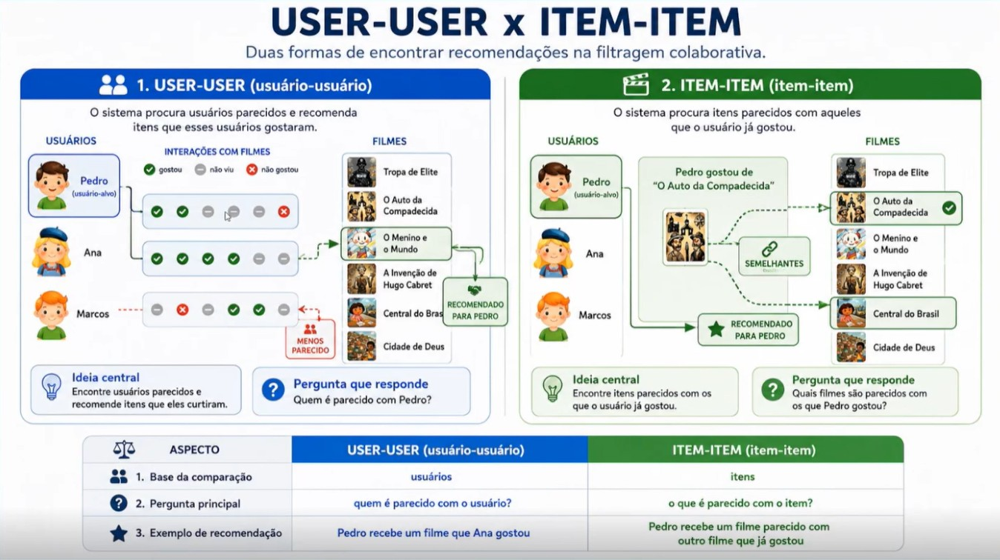

In [34]:
Image('./imagens/aula_05_007.jpg', width=1100)

## Recomendação Colaborativa Memory-based User x User

<font color='blue'>**Memory-based User x User**</font>
* Usa a similaridade (vizinhança) dos dados para estimar as avaliações (geralmente, a matriz é mantida em memória)
* A recomendação colaborativa baseada em memória utiliza diretamente os dados históricos de interação (ratings, compras, cliques) para gerar recomendações, sem treinar um modelo preditivo complexo
* A ideia central é simples
    * Usuários semelhantes tendem a gostar de itens semelhantes
    * Itens semelhantes tendem a ser consumidos pelos mesmos usuários
* Essas “semelhanças” definem a vizinhança (neighborhood)

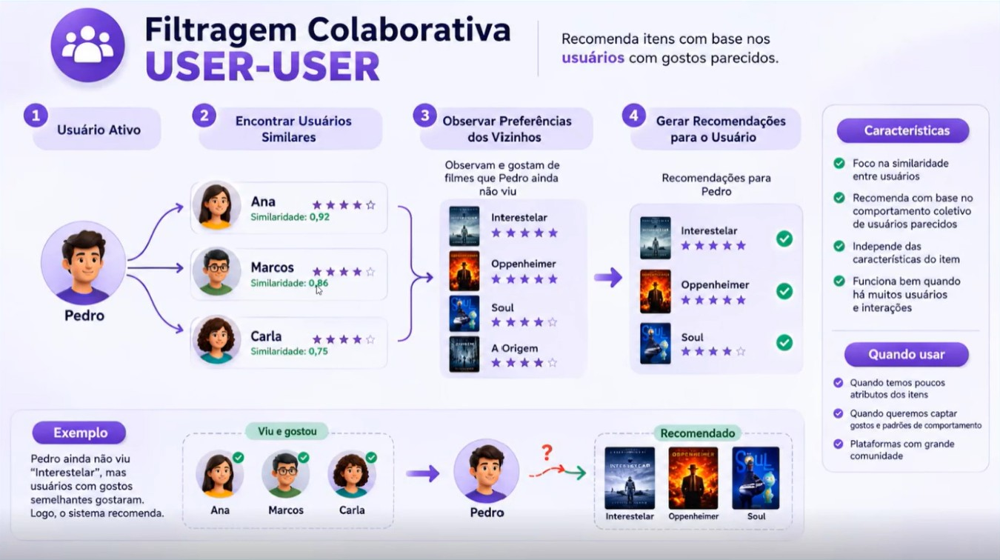

In [35]:
Image('./imagens/aula_05_008.jpg', width=1100)

### Dados de exemplo

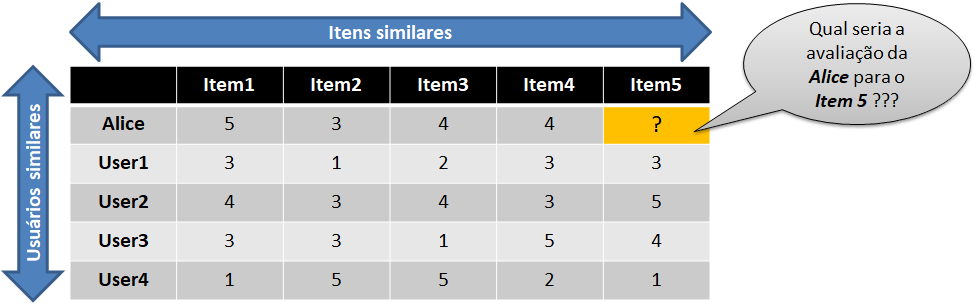

In [36]:
m_ratings = pd.DataFrame(
    {
        "Item1": [5, 3, 4, 3, 1],
        "Item2": [3, 1, 3, 3, 5],
        "Item3": [4, 2, 4, 1, 5],
        "Item4": [4, 3, 3, 5, 2],
        "Item5": [np.nan, 3, 5, 4, 1],
    },
    index=["Alice", "User1", "User2", "User3", "User4"]
)

m_ratings

,Item1,Item2,Item3,Item4,Item5
Alice,5,3,4,4,NaN
User1,3,1,2,3,3.0
User2,4,3,4,3,5.0
User3,3,3,1,5,4.0
User4,1,5,5,2,1.0


### Similaridade entre usuários

A ideia é:

> **Usuários que avaliaram itens de maneira semelhante no passado tendem a apresentar preferências semelhantes no futuro.**

Utilizaremos **correlação de Pearson**, que é adequada para comparar padrões de avaliação considerando diferenças na escala média usada por cada usuário.

Cáculo da Similiradade por coeficiente de Perason

$$
\mathrm{sim}(a,b) =
\frac{
\sum_{p \in P} (r_{a,p} - \bar{r}_a)(r_{b,p} - \bar{r}_b)
}{
\sqrt{\sum_{p \in P} (r_{a,p} - \bar{r}_a)^2}
\sqrt{\sum_{p \in P} (r_{b,p} - \bar{r}_b)^2}
}
$$

In [37]:
# Matriz
user_similarity = m_ratings.T.corr(method="pearson")
display(user_similarity.round(3))

,Alice,User1,User2,User3,User4
Alice,1.000,0.853,0.707,0.000,-0.792
User1,0.853,1.000,0.468,0.490,-0.900
User2,0.707,0.468,1.000,-0.161,-0.467
User3,0.000,0.490,-0.161,1.000,-0.642
User4,-0.792,-0.900,-0.467,-0.642,1.000


### Similaridade de `Alice` com os demais usuários

<font color='blue'>**Usuários 1 e 2 são os mais similares a Alice**</font>

In [38]:
similaridades_alice = (
    user_similarity["Alice"]
    .drop("Alice")
    .sort_values(ascending=False)
)

similaridades_alice.to_frame("similaridade")

,similaridade
User1,0.852803
User2,0.707107
User3,0.000000
User4,-0.792118


Usuários similares tendem a ter avaliações similares para os mesmos itens

Uma função de similaridade irá computar a similaridade de um usuário com todos os demais usuários a partir de suas avaliações

Se usuários diferentes avaliaram itens de forma similar no passado, então as avaliações de um dado item podem ajudar a predizer a avaliação deste item para outros usuários similares

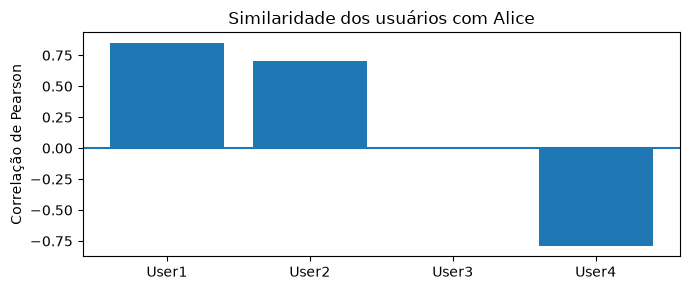

In [39]:
plt.figure(figsize=(7, 3))
plt.bar(
    similaridades_alice.index,
    similaridades_alice.values
)
plt.axhline(0)
plt.ylabel("Correlação de Pearson")
plt.title("Similaridade dos usuários com Alice")
plt.tight_layout()
plt.show()

In [40]:
similaridades_alice[ similaridades_alice > 0 ]

User1    0.852803
User2    0.707107
Name: Alice, dtype: float64

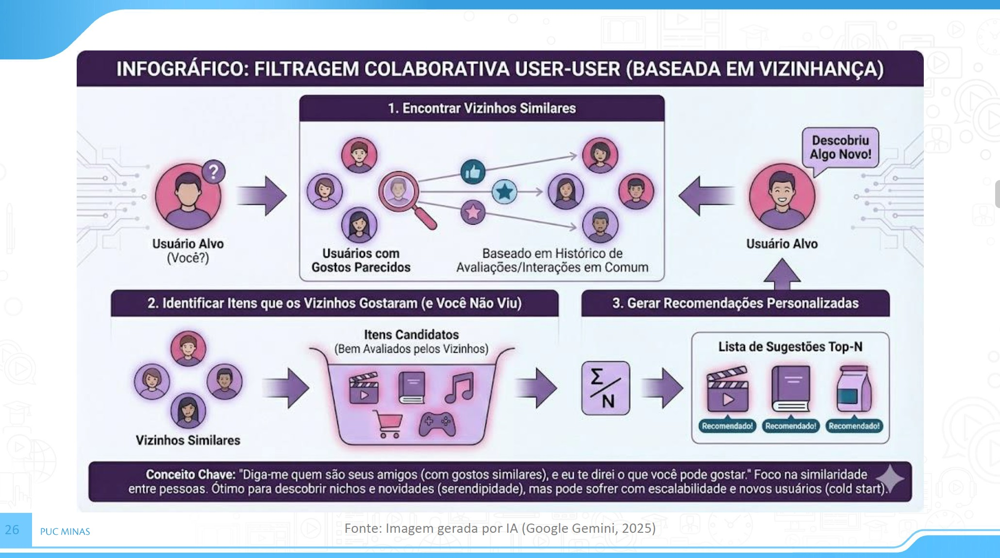

In [41]:
Image('./imagens/aula_05_006.jpg',width=1000)

### Predizendo a nota de `Alice` para o `Item 5` na abordagem `User-User`

Passo a passo
1. Calcular similaridade entre usuários (cosseno ou pearson)
2. Selecionar os N usuários mais similares (vizinhos)
3. Agregar as avaliações desses vizinhos
4. Gerar recomendação

Para `User-User`, uma forma clássica é ajustar a contribuição de cada vizinho pela média das notas desse usuário:

$$\hat r_{a,p} =
\bar r_a
+
\frac{
\sum_{b \in N}
sim(a,b)(r_{b,p}-\bar r_b)
}{
\sum_{b \in N}|sim(a,b)|
}
$$

- $\mathrm{sim}(a,b)$ é a similaridade entre $u_a$ e $u_b$
- $\bar{r}_a$ é a avaliação média do $u_a$
- $\bar{r}_b$ é a avaliação média do $u_b$
- $r_{a,p}$ é a avaliação do $u_a$ para o item $i_p$
- $r_{b,p}$ é a avaliação do $u_b$ para o item $i_p$
- $N$ é quantidade escolhida de usuários mais similares

$\hat r_{a,p}$ = Corresponde a uma ponderação a partir do calculo da similaridade e das avaliações que os usuários fizeram

Cáculo da Similiradade por coeficiente de Perason

$$
\mathrm{sim}(a,b) =
\frac{
\sum_{p \in P} (r_{a,p} - \bar{r}_a)(r_{b,p} - \bar{r}_b)
}{
\sqrt{\sum_{p \in P} (r_{a,p} - \bar{r}_a)^2}
\sqrt{\sum_{p \in P} (r_{b,p} - \bar{r}_b)^2}
}
$$

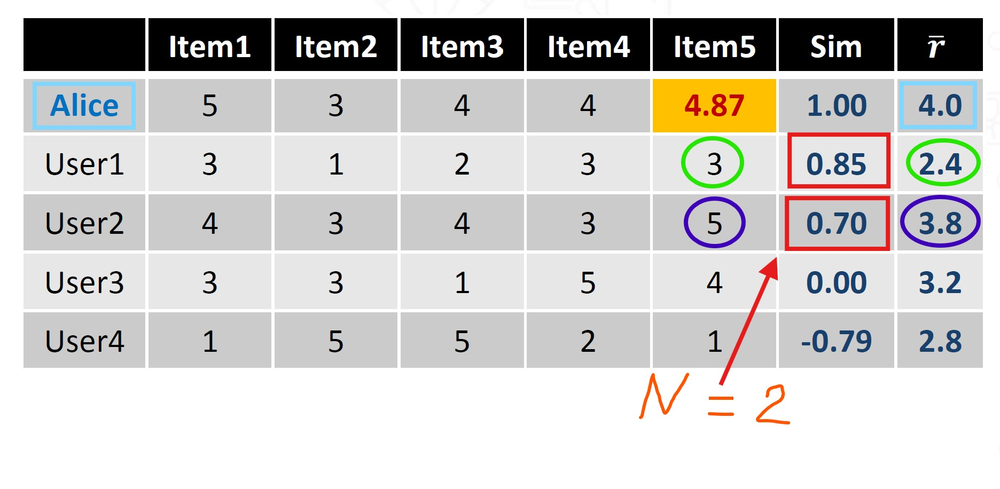

In [42]:
Image('./imagens/aula_05_009.jpg', width=1000)

**Realizando as predições para o usuário $u_a$ (Alice) para o item $i_p$ (item 5) com N = 2 usuários mais similares**

$ \hat r_{a,p} =
\bar r_a
+
\frac{
\sum_{b \in N}
sim(a,b)(r_{b,p}-\bar r_b)
}{
\sum_{b \in N}|sim(a,b)|
}
$

$\hat r_{a,p} = \frac{5+3+4+4}{4} + \left( \frac{0.85 \cdot (3-2.4) + 0.70 \cdot (5-3.8)}{0.85+0.70} \right)$

$\hat r_{a,p} = 4 + \left( \frac{0.85 \cdot 0.6 + 0.70 \cdot 1.2}{1.55} \right)$

$\hat r_{a,p} = 4 + \left( \frac{0.51 + 0.84}{1.55} \right)$

$\hat r_{a,p} = 4 + 0.87 = 4.87$

**A nota predita de 4.87 corresponde à média ponderada das avaliações dos dois usuários mais similares a Alice, considerando os respectivos coeficientes de similaridade como pesos e as notas médias desses usuários.**

### Implementação da função de predição

In [43]:
def predict_user_user(
    matrix,
    target_user,
    target_item,
    k=2
):
    similarities = (
        matrix.T
        .corr(method="pearson")[target_user]
        .drop(target_user)
        .dropna()
        .sort_values(ascending=False)
    )

    valid_users = matrix[target_item].dropna().index

    neighbors = similarities[
        similarities.index.isin(valid_users)
    ]

    neighbors = neighbors[
        neighbors > 0
    ].head(k)

    if len(neighbors) == 0:
        return np.nan, neighbors

    target_mean = matrix.loc[target_user].mean()

    numerator = 0.0
    denominator = 0.0

    for neighbor, sim in neighbors.items():
        neighbor_mean = matrix.loc[neighbor].mean()
        rating = matrix.loc[neighbor, target_item]

        numerator += sim * (rating - neighbor_mean)
        denominator += abs(sim)

    prediction = target_mean + numerator / denominator

    return prediction, neighbors

In [44]:
pred_alice, vizinhos = predict_user_user(
    m_ratings,
    target_user="Alice",
    target_item="Item5",
    k=2
)
print(f"Predição da Alice para o Item 5: {pred_alice:.2f}")

Predição da Alice para o Item 5: 4.87


# Recomendação Colaborativa Memory-based  Item x Item

## Similaridade entre itens

<font color='blue'>**Memory-based Item-Item**</font>

Agora mudamos a perspectiva:

> **Itens que recebem avaliações semelhantes dos mesmos usuários podem ser considerados próximos.**

Na abordagem `Item-Item`, **o próprio histórico do usuário** é usado para descobrir quais itens semelhantes aos que ele já avaliou podem ser recomendados.

Exemplo
* Usuário comprou Notebook
* Muitos usuários também compraram Mouse
* Mouse é recomendado

Muito comum em e-commerce (“frequentemente comprados juntos”)

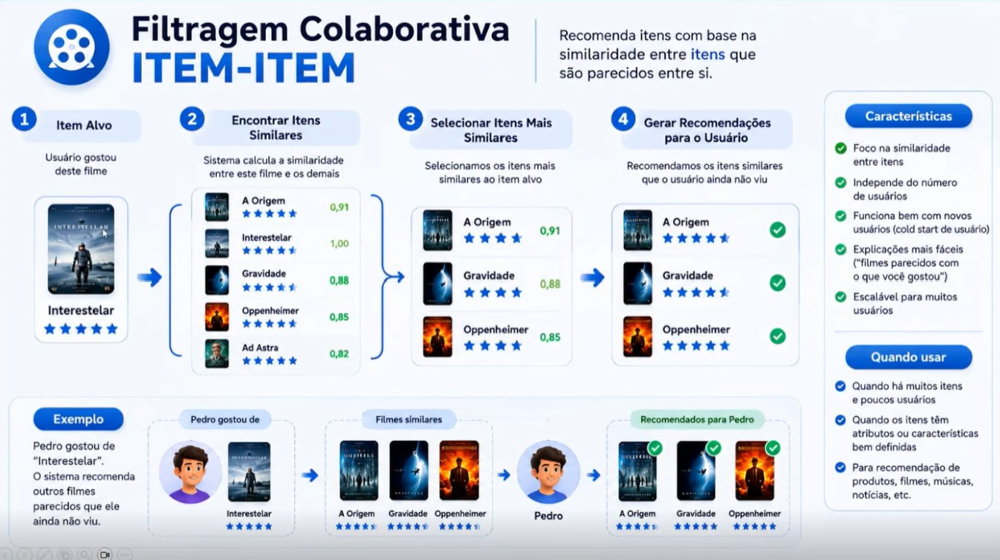

In [45]:
Image('./imagens/aula_05_010.jpg', width=1000)

### Dados de exemplo

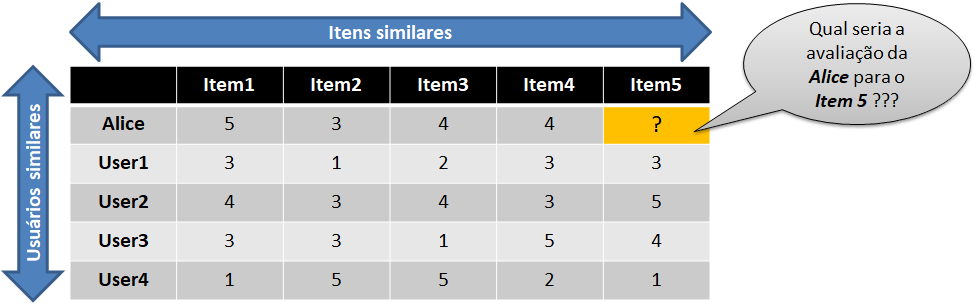

In [46]:
m_ratings = pd.DataFrame(
    {
        "Item1": [5, 3, 4, 3, 1],
        "Item2": [3, 1, 3, 3, 5],
        "Item3": [4, 2, 4, 1, 5],
        "Item4": [4, 3, 3, 5, 2],
        "Item5": [np.nan, 3, 5, 4, 1],
    },
    index=["Alice", "User1", "User2", "User3", "User4"]
)

m_ratings

,Item1,Item2,Item3,Item4,Item5
Alice,5,3,4,4,NaN
User1,3,1,2,3,3.0
User2,4,3,4,3,5.0
User3,3,3,1,5,4.0
User4,1,5,5,2,1.0


In [47]:
# Inserindo as médias
m_ratings_mean = m_ratings.copy()
m_ratings_mean["Média Usuário"] = [4, 2.4, 3.8, 3.2, 2.8]

m_ratings_mean

,Item1,Item2,Item3,Item4,Item5,Média Usuário
Alice,5,3,4,4,NaN,4.0
User1,3,1,2,3,3.0,2.4
User2,4,3,4,3,5.0,3.8
User3,3,3,1,5,4.0,3.2
User4,1,5,5,2,1.0,2.8


### Cosseno ajustado

Para comparar itens, vamos centralizar as avaliações pela média de cada usuário:

$
r'_{u,i} = r_{u,i} - \bar r_u
$

Depois calculamos a similaridade do cosseno entre os itens.

In [48]:
# Diferença entre as notas de avaliação de cada item e a respectiva nota média de cada usuário.
user_means = m_ratings.mean(axis=1)

ratings_centered = (
    m_ratings
    .sub(user_means, axis=0)
)

ratings_centered

,Item1,Item2,Item3,Item4,Item5
Alice,1.0,-1.0,0.0,0.0,NaN
User1,0.6,-1.4,-0.4,0.6,0.6
User2,0.2,-0.8,0.2,-0.8,1.2
User3,-0.2,-0.2,-2.2,1.8,0.8
User4,-1.8,2.2,2.2,-0.8,-1.8


**Cálculo da similaridade pelo cosseno ajustado**

$$
\mathrm{sim}(a,b) =
\frac{
\sum_{u \in U} (r_{u,a} - \bar{r}_u)(r_{u,b} - \bar{r}_u)
}{
\sqrt{\sum_{u \in U} (r_{u,a} - \bar{r}_u)^2}
\sqrt{\sum_{u \in U} (r_{u,b} - \bar{r}_u)^2}
}
$$

- $\mathrm{sim}(a,b)$ é a similaridade entre $i_a$ e $i_b$
- $\bar{r}_u$ é a avaliação média do usuário $u$
- $r_{u,a}$ é a avaliação do $u$ para o item $i_a$
- $r_{u,b}$ é a avaliação do $u$ para o item $i_b$

In [49]:
# Matriz
item_similarity_adjusted = pd.DataFrame(
    cosine_similarity(
        ratings_centered.T.fillna(0)
    ),
    index=m_ratings.columns,
    columns=m_ratings.columns
)

item_similarity_adjusted.round(3)

,Item1,Item2,Item3,Item4,Item5
Item1,1.000,-0.940,-0.547,0.268,0.714
Item2,-0.940,1.000,0.621,-0.361,-0.853
Item3,-0.547,0.621,1.000,-0.881,-0.764
Item4,0.268,-0.361,-0.881,1.000,0.433
Item5,0.714,-0.853,-0.764,0.433,1.000


### Similaridade do `Item 5` com os demais itens

In [50]:
similaridades_item5 = (
    item_similarity_adjusted["Item5"]
    .drop("Item5")
    .sort_values(ascending=False)
)

similaridades_item5.to_frame("similaridade")

,similaridade
Item1,0.713758
Item4,0.433063
Item3,-0.763560
Item2,-0.853001


Itens similares tem avaliações similares para os mesmos usuários

Uma função de similaridade irá computar a similaridade de um item com todos os demais itens a partir de suas avaliações

Se itens foram avaliados de forma similar no passado, então a avaliação de um item para um usuário pode ajudar a predizer a avaliação de outro item similar para outro usuário

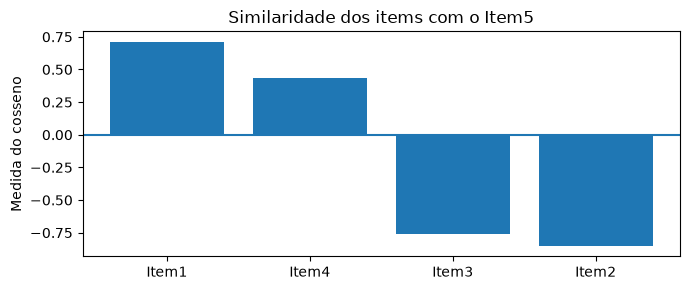

In [51]:
plt.figure(figsize=(7, 3))
plt.bar(
    similaridades_item5.index,
    similaridades_item5.values
)
plt.axhline(0)
plt.ylabel("Medida do cosseno")
plt.title("Similaridade dos items com o Item5")
plt.tight_layout()
plt.show()

In [52]:
similaridades_item5[ similaridades_item5 > 0 ]

Item1    0.713758
Item4    0.433063
Name: Item5, dtype: float64

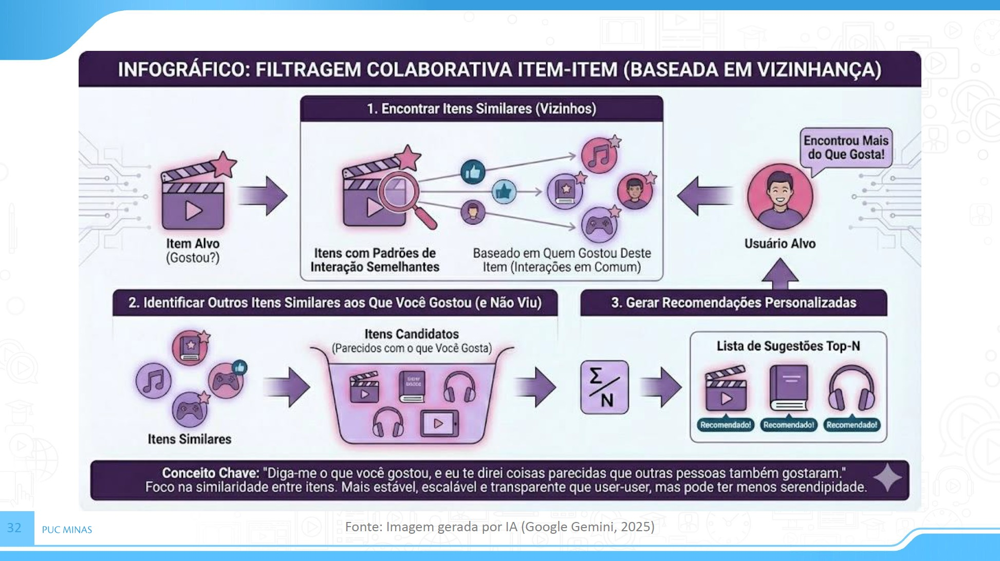

In [53]:
Image('./imagens/aula_05_012.jpg', width=1000)

## Predizendo a nota de `Alice` para o `Item 5` na abordagem `Item-Item`

Passo a passo
1. Calcular similaridade entre itens
2. Encontrar itens similares aos já consumidos
3. Recomendar os mais próximos

Uma forma simples de estimar a nota é calcular a média ponderada das avaliações que Alice já fez em itens semelhantes:


$$
\hat r_{a,p} =
\frac{
\sum_{b \in N} \mathrm{sim}(a,b) \cdot r_{b,p}
}{
\sum_{b \in N} \mathrm{sim}(a,b)
}
$$

- $\mathrm{sim}(a,b)$ é a similaridade entre $i_a$ e $i_b$
- $r_{b,p}$ é a avaliação do $u_b$ para o item $i_p$

**Cáculo da Similaridade por cosseno ajustado**

$$
\mathrm{sim}(a,b) =
\frac{
\sum_{u \in U} (r_{u,a} - \bar{r}_u)(r_{u,b} - \bar{r}_u)
}{
\sqrt{\sum_{u \in U} (r_{u,a} - \bar{r}_u)^2}
\sqrt{\sum_{u \in U} (r_{u,b} - \bar{r}_u)^2}
}
$$

- $\mathrm{sim}(a,b)$ é a similaridade entre $i_a$ e $i_b$
- $\bar{r}_u$ é a avaliação média do usuário $u$
- $r_{u,a}$ é a avaliação do $u$ para o item $i_a$
- $r_{u,b}$ é a avaliação do $u$ para o item $i_b$

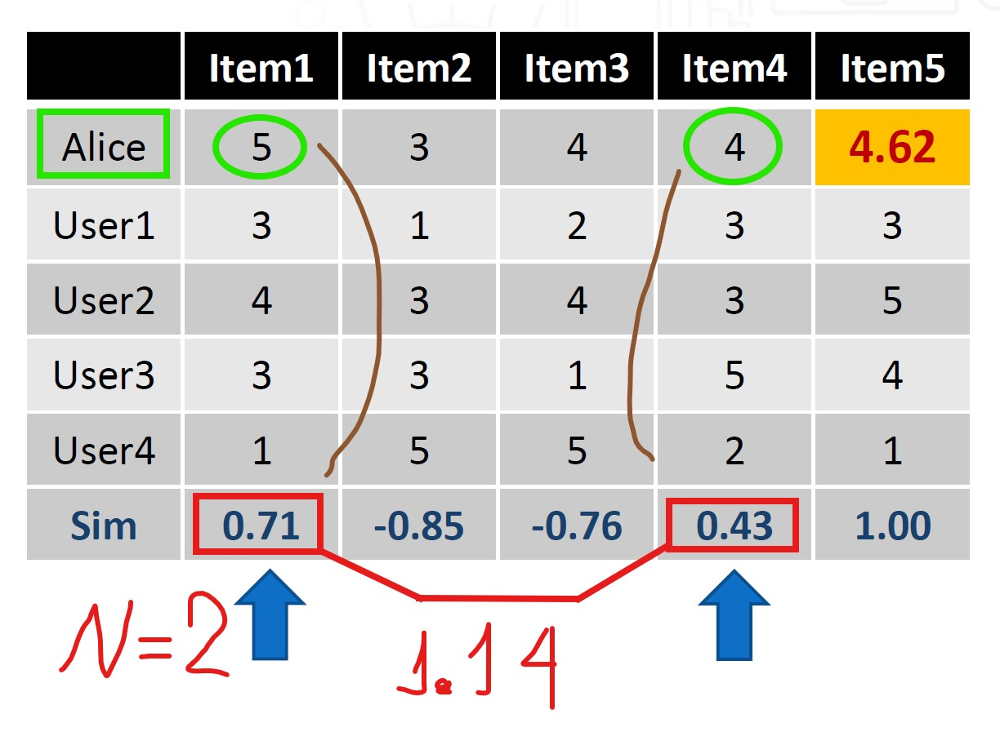

In [54]:
Image('./imagens/aula_05_013.jpg',  width=650)

<font color='blue'>**Realizando as predições para o usuário $u_a$ (alice) para o item $i_p$ (item 5) com N=2 itens mais similares**</font>

$
\hat r_{a,p} =
\frac{
\sum_{b \in N} \mathrm{sim}(a,b) \cdot r_{b,p}
}{
\sum_{b \in N} \mathrm{sim}(a,b)
}
$


$\hat r_{a,p} = \dfrac{(0.71 \cdot 5.0) + (0.43 \cdot 4.0)}{0.71 + 0.43}$

$\hat r_{a,p} = \dfrac{3.57 + 1.73}{1.14}$

$\hat r_{a,p} = \dfrac{5.30}{1.14} = 4.62$

**A nota predita de 4.62 corresponde à média ponderada das avaliações dos dois itens mais similares ao item 5, considerando os respectivos coeficientes de similaridade como pesos e as notas avaliadas da alice para os item mais similares.**

### Implementação da função de predição

In [55]:
def predict_item_item(
    matrix,
    target_user,
    target_item,
    k=2
):
    means = matrix.mean(axis=1)

    centered = matrix.sub(
        means,
        axis=0
    )

    sims = pd.DataFrame(
        cosine_similarity(
            centered.T.fillna(0)
        ),
        index=matrix.columns,
        columns=matrix.columns
    )

    user_ratings = (
        matrix.loc[target_user]
        .dropna()
    )

    similarities = (
        sims.loc[
            target_item,
            user_ratings.index
        ]
        .sort_values(ascending=False)
    )

    similarities = similarities[
        similarities > 0
    ].head(k)

    if len(similarities) == 0:
        return np.nan, similarities

    numerator = sum(
        similarities[item]
        * user_ratings[item]
        for item in similarities.index
    )

    denominator = np.abs(
        similarities
    ).sum()

    prediction = numerator / denominator

    return prediction, similarities

In [56]:
pred_item, itens_vizinhos = predict_item_item(
    m_ratings,
    target_user="Alice",
    target_item="Item5",
    k=2
)

print(
    f"Predição da Alice para o Item 5: {pred_item:.2f}"
)

Predição da Alice para o Item 5: 4.62


## Comparação User-User × Item-Item


| User-User | Item-Item |
|---|---|
| Encontra usuários semelhantes | Encontra itens semelhantes |
| Vizinhança pode mudar bastante | Relações entre itens tendem a ser mais estáveis |
| Pode favorecer diversidade | Costuma ser escalável e explicável |
| Usa avaliações dos vizinhos | Usa avaliações do próprio usuário |

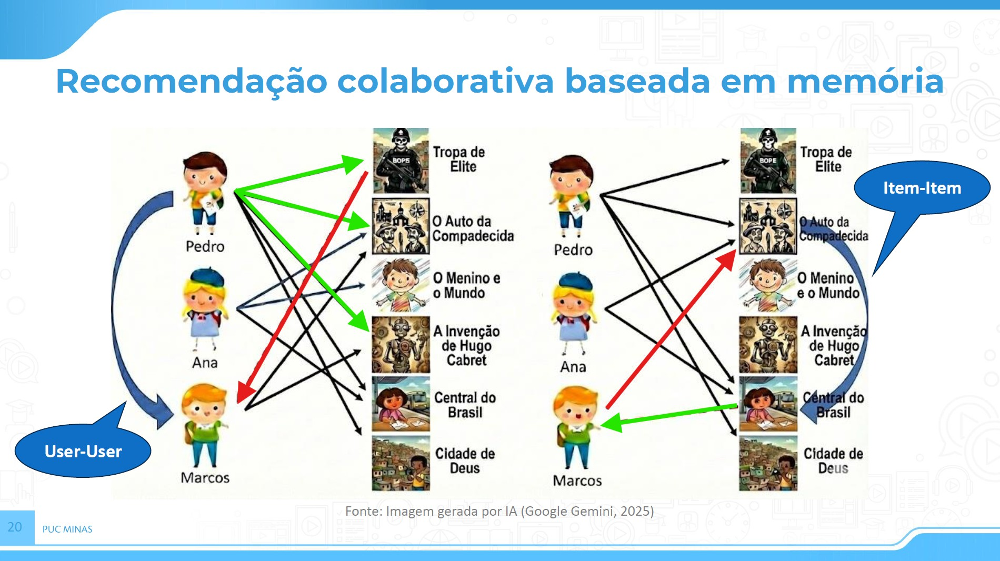

In [57]:
Image('./imagens/aula_05_014.jpg', width=1000)

As duas abordagens são **memory-based**: utilizam diretamente os dados históricos para calcular as relações.

* Em geral, Item-Item consegue recomendações mais relevantes
    * As avaliações do próprio usuário são consideradas

* Item-Item é mais estável às mudanças de avaliações, mais escalável e transparente

* User-User fornece mais diversidade e novidade (serendipidade), mas é menos estável

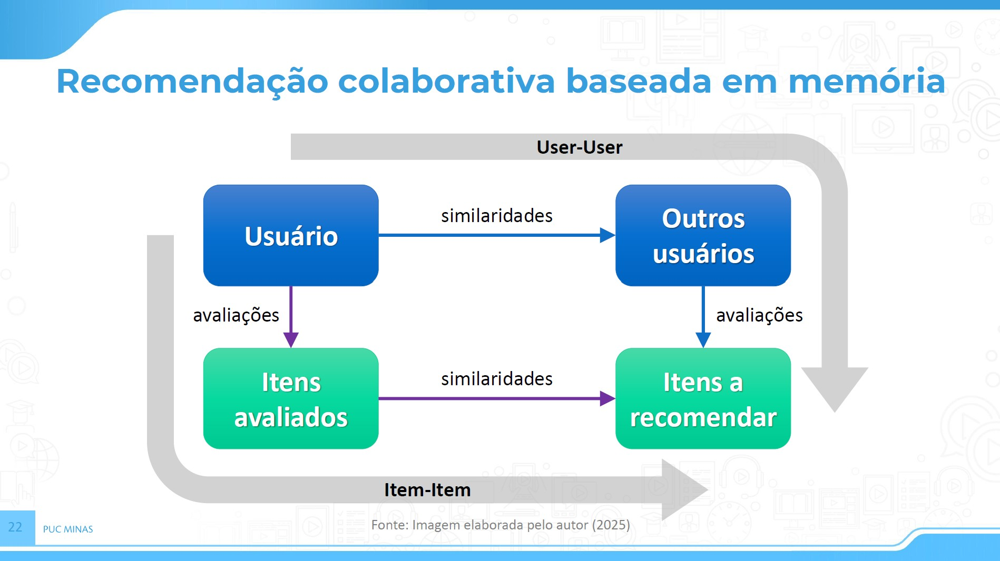

In [58]:
Image('./imagens/aula_05_016.jpg', width=1000)

# Recomentação colaborativa com dataset MovieLens

## Memory-Based Item-Item - Quem gostou deste filme, vai gostar de...

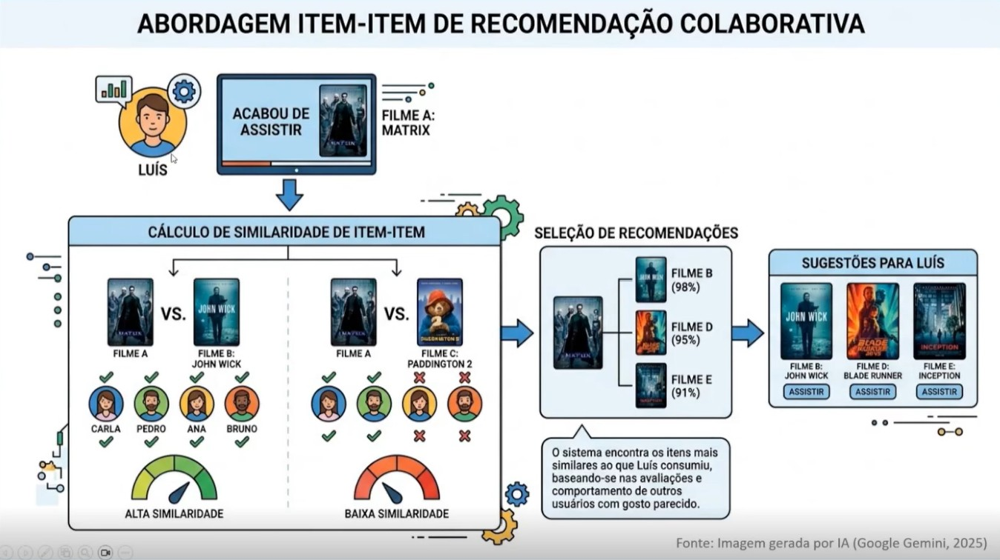

In [59]:
Image('./imagens/aula_05_011.jpg', width=1000)

## Carregando os arquivos

In [60]:
MOVIES_URL  = "./datasets/movies_imdb.csv"
RATINGS_URL = "./datasets/ratings_imdb.csv"

# dataset com informações dos filmes
movies = pd.read_csv(
    MOVIES_URL,
    encoding="latin-1",
    low_memory=False
)

# dataset com as avaliações
ratings = pd.read_csv(
    RATINGS_URL,
    encoding="latin-1",
    low_memory=False
)

In [61]:
movies["tags"] = movies["tags"].fillna("")
movies = movies.set_index("movieId")

print(f"Filmes: {len(movies)}")
print(f"Avaliações: {len(ratings)}")
print(f"Usuários: {ratings['userId'].nunique()}")

display(movies.head())
display(ratings.head())

Filmes: 9724
Avaliações: 100836
Usuários: 610


,title,genres,tags,tag_count,vote_count,vote_average,imdb_score
movieId,,,,,,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar,2,215,3.920930,3.894473
2,Jumanji,Adventure|Children|Fantasy,fantasy magic_board_game game robin_williams,4,110,3.431818,3.419009
3,Grumpier Old Men,Comedy|Romance,old moldy,2,52,3.259615,3.260033
4,Waiting to Exhale,Comedy|Drama|Romance,,0,7,2.357143,2.866377
5,Father of the Bride Part II,Comedy,pregnancy remake,2,49,3.071429,3.101070


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## Matriz de Usuários x Itens

In [62]:
ratings_matrix = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Shape da matriz usuário × item:", ratings_matrix.shape)
ratings_matrix.iloc[:10, :20]

Shape da matriz usuário × item: (610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
userId,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,4.0,5.0,3.0,5.0,4.0,4.0,3.0,NaN,3.0,4.0,NaN,3.0,NaN,4.0,4.0,4.0,NaN,2.0,NaN
7,4.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Matriz de avaliação é esparsa**

* 9724 colunas (filmes)  x 610 (usuários)
* A maior parte dos valores são nulos
* Diluição dos valores das avaliações devido a alta dimensionalidade do espaço de dados.
* Usuários não assitiram a maior parte dos filmes do catálogo

## Recomendações para um filme específico

> Usuários que avaliaram este filme também avaliaram de forma semelhante estes outros filmes.

### Formatar os dados para a biblioteca [Surprise](https://surpriselib.com/)

**Biblioteca Suprise é dedicada a sistema colaborativos**

* A biblioteca Surprise foi desenvolvida para algoritmos de recomendação baseados em avaliações explícitas.

* Não tem suporte para avalições implícitas

    * Significa que ela foi projetada principalmente para trabalhar com notas explícitas atribuídas pelos usuários aos itens, e não com sinais indiretos de preferência, como cliques, visualizações, se adicionou o filme, concluiu o filma, ou compras.

In [63]:
import surprise
reader = Reader(rating_scale=(0, 5))

# Suprise faz a carga dos dados a partir de um dataframe
# --> Informa coluna de usuario, item e a avaliacao
data = surprise.Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)

# arquivos de treino e teste
trainset = data.build_full_trainset()
testset = trainset.build_testset()

# arquivo de dados ausentes
# Coloca para todos os usuários todos os filmes que ele não viu
# facilita no processo de recomendação de filmes que o usuário não viu
ausentes = trainset.build_anti_testset()

### Recuperar os filmes vizinhos (Item-Item)

Computar a similaridade entre os itens

In [64]:
# parametro do algoritmo de vizinhaça KNN
# "name": "pearson_baseline" --> Cálcula a Similaridade por coeficiente de pearson
# "user_based": False --> configura para estratégia item-item
sim_options = {"name": "pearson_baseline", "user_based": False}  # item - item

# algoritmo de vizinhaça KNN
modelo_itens = KNNBaseline(sim_options=sim_options)
modelo_itens.fit(trainset)


Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.


In [65]:
# Função recebe um filme e a biblioteca traz os vizinhos mais próximos
# 
def get_itens_vizinhos(movieId, k=10):
    
    # iid 
    #    --> converte o código do filme do dataset MovieLens para o código interno do item na Surprise
    # Em "data = surprise.Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)" 
    #   --> codigo do MovieLens é modificado para um código interno na biblioteca Surprise
    iid = trainset.to_inner_iid(movieId)

    # traz oss vizinhos mais proximo
    aux = modelo_itens.get_neighbors(iid,k)

    # Lista do k vizinhos mais próximos
    return [modelo_itens.trainset.to_raw_iid(inner_id) for inner_id in aux]

### Função para retornar as recomendações

#### Filme Toy Story

In [66]:
# recomendação para o filme movieid = 1
# --> Saida é uma lista python
get_itens_vizinhos(1)

[3114, 588, 8961, 6377, 1270, 78499, 34, 1097, 2716, 4886]

**Os filmes [3114, 588, 8961, 6377, 1270, 78499, 34, 1097, 2716, 4886] foram recomendados apenas pelas notas de avaliação dos usuários**

Não foram utilizadas informações sobre os filmes ou comportamento e perfil dos usuários que avaliaram.

As recomendações item-item são personalizadas pela similaridade dos vizinhos 

--> Usando os vizinhos que tiveram o mesmo compartamento ao avaliar os mesmos filmes vistos de forma similar.

--> Traz filmes que tiveram avaliações similares 

In [67]:
# filme movieid = 1 --> Toy Story
movies[ movies.index.isin([1]) ]

,title,genres,tags,tag_count,vote_count,vote_average,imdb_score
movieId,,,,,,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar,2,215,3.92093,3.894473


In [68]:
def get_movie_recommendations(movie=None, k=3):

    # Seleciona o subset de filmes vizinhos
    aux = get_itens_vizinhos(movie, k)
    vizinhos = pd.DataFrame(enumerate(aux), columns=['rank','movieId']).set_index('movieId')
    return movies.loc[aux][['title','genres','imdb_score']].join(vizinhos, on='movieId').sort_values(by=['rank'])

In [69]:
# 5 Recomendações para quem viu o filme Toy Story
get_movie_recommendations(movie=1, k=5)

,title,genres,imdb_score,rank
movieId,,,,
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.810019,0
588,Aladdin,Adventure|Animation|Children|Comedy|Musical,3.767511,1
8961,"Incredibles, The",Action|Adventure|Animation|Children|Comedy,3.797478,2
6377,Finding Nemo,Adventure|Animation|Children|Comedy,3.919080,3
1270,Back to the Future,Adventure|Comedy|Sci-Fi,3.999234,4


<font color='blue'>**Quem assitiu esse filme também assistiu esse outro...**</font>

Quem assistiu "Toy Story" também assistiu / Quem gostou de "Toy Story" também gostou de ...
* Toy Story 2
* Aladdin
* Incredibles, The
* Finding Nemo
* Back to the Future

Também pode ser aplicado para outros cenários de recomendação

* Quem comprou esse produto também comprou esse outro...
* Quem gostou desse produto também gostou desses outros ...

#### Filme "Godfather, The"

In [70]:
movies[ movies.index.isin([858]) ]

,title,genres,tags,tag_count,vote_count,vote_average,imdb_score
movieId,,,,,,,
858,"Godfather, The",Crime|Drama,mafia,1,192,4.289062,4.243095


In [71]:
get_movie_recommendations(movie=858, k=5)

,title,genres,imdb_score,rank
movieId,,,,
1221,"Godfather: Part II, The",Crime|Drama,4.194652,0
1213,Goodfellas,Crime|Drama,4.184163,1
296,Pulp Fiction,Comedy|Crime|Drama|Thriller,4.170449,2
260,Star Wars: Episode IV - A New Hope,Action|Adventure|Sci-Fi,4.197546,3
527,Schindler's List,Drama|War,4.187170,4


# Recomendação baseada em modelo 

A recomendação colaborativa baseada em modelo utiliza técnicas de aprendizado de máquina e estatística para aprender um modelo preditivo a partir do histórico de interações entre usuários e itens

Diferente da abordagem baseada em memória, os dados não são usados diretamente para recomendar, mas para treinar um modelo que generaliza padrões latentes

Métodos cujo foco é prever a nota estimada que um usuário 𝑢 daria para um item 𝑖.

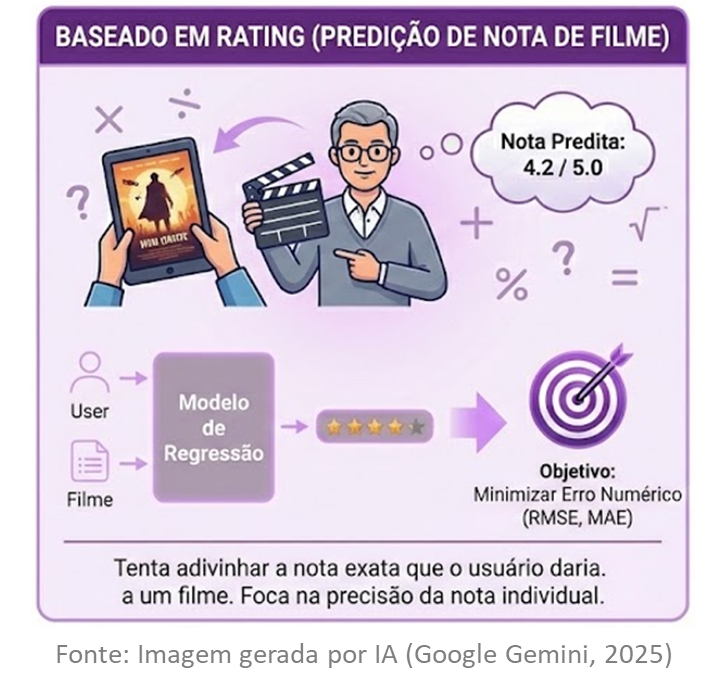

Baseado em uma etapa off-line para treinar um modelo de predição, cujo objetivo é prever os valores faltantes

* A partir das matrizes de avalições (usuários x itens)

Geração do modelo de machine learning utiliza as avaliações já realizadas pelos usuários

* O modelo gerado é usado para fazer as predições dos valores que não são conhecidos

**Técnicas baseadas em fatoração de matrizes (SVD), modelos probabilísticos e aprendizado profundo (deep learning)**

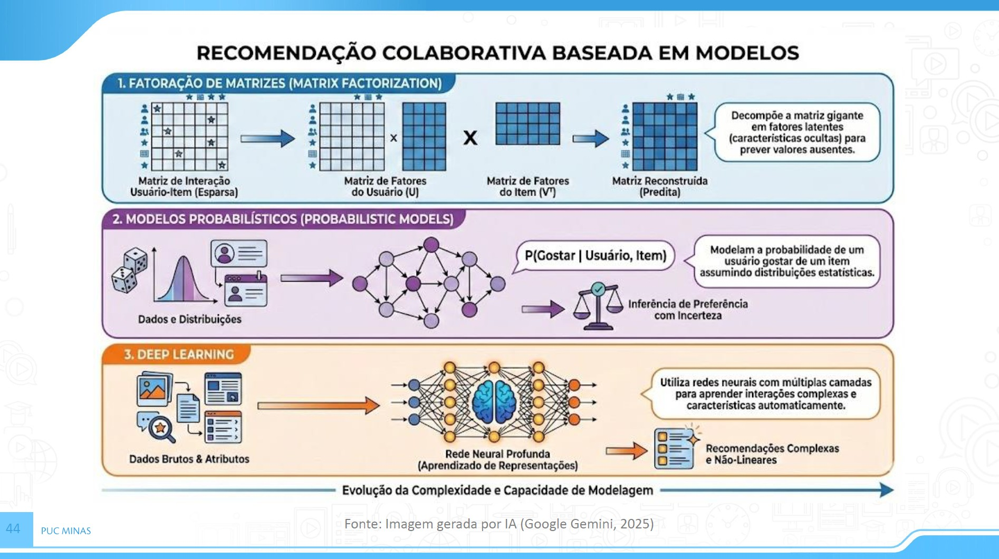

In [72]:
Image('./imagens/aula_05_018.jpg', width=1200)

# Recomendação baseada em modelo - Rating para o dataset MovieLens

## Formatar arquivos para a biblioteca [Cornac](https://cornac.readthedocs.io/en/v3.0.0/)

In [73]:
# dataset de avaliações
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


A biblioteca Cornac trabalha com dados representados por uma lista de tuplas.

Na matriz de avaliações, os elementos de cada tupla devem seguir esta ordem:

1. Usuário: identificador do usuário.
2. Item: identificador do filme.
3. Avaliação: nota atribuída pelo usuário ao filme.   

Portanto, os dados do DataFrame devem ser convertidos em uma lista de tuplas, respeitando essa ordem de informações.

In [74]:
data_cornac = list(
    ratings[
        ["userId", "movieId", "rating"]
    ].itertuples(
        index=False,
        name=None
    )
)
data_cornac[:5]

[(1, 1, 4.0), (1, 3, 4.0), (1, 6, 4.0), (1, 47, 5.0), (1, 50, 5.0)]

**Cada avaliação (linha) do dataframe ratings virou uma tupla dentro da lista**

In [75]:
# Gerando o dataset com a biblioteca cornac a partir da lista de tuplas do dataset rating do MovieLens
dataset = cornac.data.Dataset.from_uir(
    data_cornac
)

## Criar o ***user profile***

### Criar a matriz de gêneros

**Mapear as características dos filmes a serem utilizadas na montagem do user profile**

A coluna ``genres`` traz a informação de quais gêneros o filme foi classificado. Sendo que um filme pode ter mais de um gênero.

Essa informação textual será convertida em uma matriz númerica

In [76]:
def transf_genero(g):
    g = str(g).lower()
    return g.replace("(no genres listed)", "unknown")


all_genres = [
    item
    for genres in movies["genres"].fillna("")
    for item in genres.split("|")
]

unique_genres = sorted({transf_genero(g) for g in all_genres if g})

movie_genres = pd.DataFrame(
    0.0,
    index=movies.index,
    columns=unique_genres
)

for movie_id, genres in movies["genres"].fillna("").items():
    for genre in genres.split("|"):
        if genre:
            movie_genres.loc[movie_id, transf_genero(genre)] = 1.0

movie_genres.head()

,action,adventure,animation,children,comedy,crime,documentary,drama,fantasy,film-noir,horror,imax,musical,mystery,romance,sci-fi,thriller,unknown,war,western
movieId,,,,,,,,,,,,,,,,,,,,
1,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Cada linha representa um filme do catálogo, enquanto as colunas correspondem aos gêneros cinematográficos existentes no catálogo.

Para cada filme, atribui-se o valor 1 às colunas correspondentes aos seus gêneros e 0 às colunas dos gêneros aos quais ele não pertence.

### Normalizando a contribuição de cada filme


Como um filme pode ter vários gêneros, vamos distribuir o peso do filme entre os seus gêneros para evitar que um filme com quatro gêneros possa influenciar o perfil mais que um filme com apenas um gênero.

In [77]:
movie_genres_norm = movie_genres.div(
    movie_genres.sum(axis=1).replace(0, 1),
    axis=0
)

movie_genres_norm.head()

,action,adventure,animation,children,comedy,crime,documentary,drama,fantasy,film-noir,horror,imax,musical,mystery,romance,sci-fi,thriller,unknown,war,western
movieId,,,,,,,,,,,,,,,,,,,,
1,0.0,0.200000,0.2,0.200000,0.200000,0.0,0.0,0.000000,0.200000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
2,0.0,0.333333,0.0,0.333333,0.000000,0.0,0.0,0.000000,0.333333,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
3,0.0,0.000000,0.0,0.000000,0.500000,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.500000,0.0,0.0,0.0,0.0,0.0
4,0.0,0.000000,0.0,0.000000,0.333333,0.0,0.0,0.333333,0.000000,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.0,0.0,0.0
5,0.0,0.000000,0.0,0.000000,1.000000,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0


Dividiu o peso 1 dos generos do filme pela quantidade de categorias de genero que o filme foi classificado.

**Filme 1**  Movieid = 1  

-->  Toy Story	Adventure|Animation|Children|Comedy|Fantasy	

--> Toy Story	$\frac{1}{5}$ | $\frac{1}{5}$ |$\frac{1}{5}$ | $\frac{1}{5}$ | $\frac{1}{5}$	

--> Toy Story	0.2 | 0.2 | 0.2 | 0.2 | 0.2

### Função `create_user_profile()`

In [78]:
def create_user_profile(
    user=None,
    user_ratings=None,
    positive_threshold=4.0
):
    if (user is None) == (user_ratings is None):
        raise ValueError(
            "Informe exatamente um entre 'user' ou 'user_ratings'."
        )

    if user is not None:
        user_ratings = (
            ratings[
                (ratings["userId"] == user)
                & (ratings["rating"] >= positive_threshold)
            ][["movieId", "rating"]]
            .set_index("movieId")
        )
    else:
        user_ratings = user_ratings.copy()

        if "movieId" in user_ratings.columns:
            user_ratings = user_ratings.set_index("movieId")

    # Mantém somente filmes existentes na matriz de conteúdo.
    ids_validos = user_ratings.index.intersection(
        movie_genres_norm.index
    )

    user_ratings = user_ratings.loc[ids_validos]

    if len(user_ratings) == 0:
        raise ValueError(
            "Não há avaliações positivas suficientes para criar o perfil."
        )

    item_features = movie_genres_norm.loc[
        user_ratings.index
    ]

    weighted_features = item_features.mul(
        user_ratings["rating"],
        axis=0
    )

    profile = weighted_features.sum(axis=0)

    if profile.sum() > 0:
        profile = profile / profile.sum()

    return profile

A função combina três conceitos importantes:
1. Seleção de avaliações positivas: considera filmes com nota igual ou superior a positive_threshold.
2. Representação dos itens: utiliza a matriz movie_genres_norm para representar cada filme por seus gêneros.
3. Construção do perfil: agrega os vetores dos filmes avaliados, ponderando-os pelas notas atribuídas pelo usuário.

Pontos importantes na implementação

**As notas funcionam como pesos absolutos**

Isso significa que um filme avaliado com nota 5 tem mais influência do que um filme avaliado com nota 4.

É uma estratégia válida, mas existe uma particularidade: uma nota 5 não representa necessariamente uma preferência 25% maior do que uma nota 4.

Uma alternativa seria ponderar os filmes pela intensidade da preferência acima de um ponto de referência,

$$
w_{ui} = r_{ui} - 3
$$

Nesse caso, uma nota 5 teria peso 2 e uma nota 4 teria peso 1.

Essa alternativa muda o significado do perfil.

Não existe uma escolha universalmente correta: é importante definir o que os pesos devem representar.


**A normalização dos vetores dos filmes importa**

Você utiliza movie_genres_norm, mas o comportamento depende de como essa matriz foi construída.

Se ela contém indicadores binários de gêneros, a soma ponderada funciona como uma contagem de preferências por gênero.

Se os vetores foram normalizados por norma L2, a soma de seus componentes pode ser diferente para cada filme.
    
Nesse caso, a agregação pode ter outra interpretação.

**O alinhamento dos índices**    

Ele restringe os dados aos filmes que possuem características disponíveis.

Entretanto, vale garantir que movieId seja único no índice de user_ratings e em movie_genres_norm. 

Se houver avaliações repetidas para um mesmo filme, a agregação poderá produzir resultados inesperados.

### Representação gráfica do ***user profile***

In [79]:
def plot_user_profile(profile, top_n=12):
    dados = (
        profile
        .sort_values(ascending=False)
        .head(top_n)
    )

    plt.figure(figsize=(8, 3))
    plt.bar(dados.index, dados.values)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Peso no perfil")
    plt.title("Principais características do User Profile")
    plt.tight_layout()
    plt.show()

### *User profile* para um usuário específico

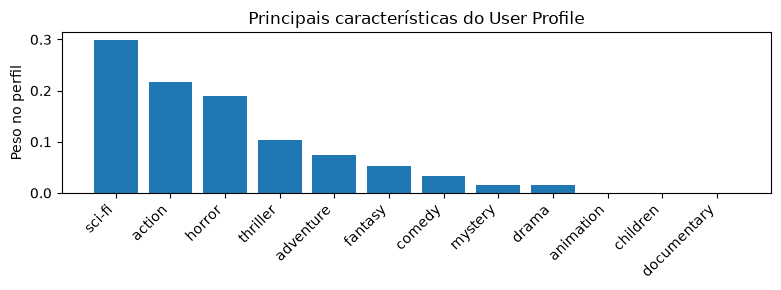

In [80]:
plot_user_profile(create_user_profile(user=3))

## Treinar modelo de *rating*

**Modelo Matrix Factorization – MF**

A partir da matriz esparsa dos usuários e avaliações do dataset MovieLens o modelo irá estimar a provável nota que o usuário daria para todos os filmes do catálogo que ele não assitiu. 

O sistema de recomendação irá recomendar os filmes com as maiores notas preditas para as menores.  

**Técnica de fatoração de Matrizes**

A fatoração de matrizes (Matrix Factorization – MF) é uma técnica de recomendação colaborativa baseada em modelo que representa usuários e itens em um espaço latente de baixa dimensão, de forma que a interação entre esses vetores explique o comportamento observado

A ideia central é
*  Preferências dos usuários e características dos itens podem ser explicadas por poucos fatores latentes não observáveis diretamente

* Matriz esparsa de avaliações --> Técnica otimização de fatoração de Matrizes --> Treinamento que irá estimar os valores faltantes e gera a matriz reconstruida da Matriz de avaliações.

**Decomposição de matrizes em valores singulares (SVD)**

Os modelos de fatoração de matrizes aplicados a recomendação, foram baseados na técnica de decomposição de matrizes em valores singulares (SVD)

Técnica de redução de dimensionalidade da álgebra linear

Uma matriz M pode ser decomposta em um produto de 3 matrizes

$$
M = U \times S \times V^{T}
$$

- $U$ e $V$ são matrizes ortogonais $m \times m$ e $n \times n$
- $S$ é uma matriz diagonal $m \times n$ (singular)

**SVD Clássico**

É possível obter uma aproximação ótima da matriz M usando outras 3 matrizes, procurando os k maiores valores singulares de S


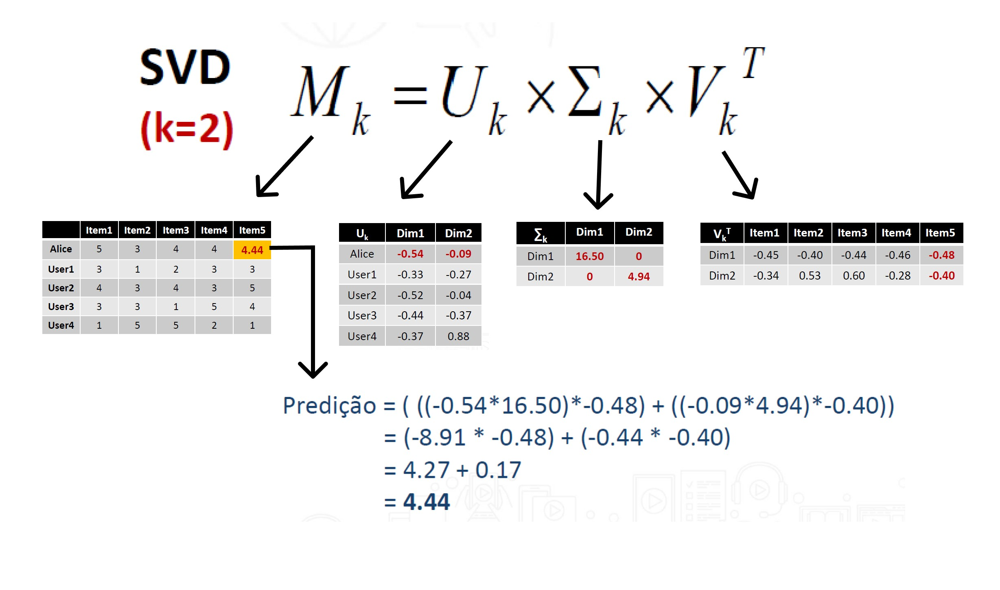

In [81]:
Image('./imagens/aula_05_020.jpg', width =1100)

**Ideia central do Modelo MF**

Como a matriz de usuários x itens é esparsa, isto é, não está totalmente preenchida, o modelo de fatoração de matrizes (MF) não usa o SVD clássico

Modelo MF auxilia na construção das matrizes $U \times S \times V^{T}$ a partir da matriz esparsa de usuários x itens X avaliações

Aprende os fatores latentes por otimização (aproximação), minimizando o erro das entradas conhecidas

Estes fatores devem explicar os ratings conhecidos

Ajudam a reconstruir (estimar) valores faltantes para as recomendações

In [82]:
modelo_rating = MF(
    k=20,
    max_iter=500,
    learning_rate=0.01,
    lambda_reg=0.02,
    use_bias=True,
    name="MF"
)

modelo_rating.fit(
    dataset
)

print("Modelo de rating treinado.")

Modelo de rating treinado.


**Catálogo de filmes**
* Usuários não escolhem filmes aleatoriamente
    * Ex: gosto por ação, preferência por romance, filmes longos
* Estes fatores não estão explicitamente nos dados
* São inferidos a partir dos padrões de avaliação
* O modelo de fatoração de matrizes (MF) aprende esses fatores automaticamente para gerar novas predições

**Fatores latentes**

Matriz de avaliação --> Não tem informação do usuário e nem filme

* Não sabe se o filme é ação, cómedia, se o usuário é homem, mulher, idoso,  autraliano, brasileiro

* Não há informação sobre os itens e  usuários,  apenas as notas

* A nota carrega implicitamente essas informações sobre o usuário e sobre os itens

Processo é desconstruir a matriz de avaliação gerando outras matrizes que vão representam tudo que está oculto.

* Fatores latentes expressam alguma coisa que levou o usuário a dar a nota para aquele item.

* De certa forma fatores ocultos combinados influenciam na nota de avaliação do item.

* Modelo MF de fatoração de matrizes trabalha na construção dessas matrizes que representam tudo que está oculto.


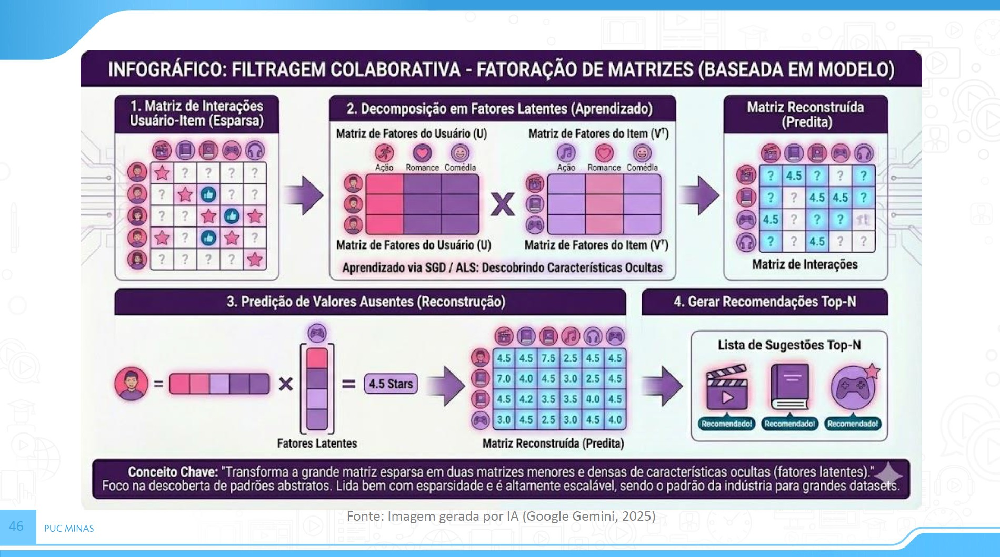

In [83]:
Image('./imagens/aula_05_019.jpg')

## Predição com modelo baseado em *rating*

In [84]:
def predict(modelo, userId, movieId):

    user_idx = modelo.train_set.uid_map[userId]
    item_idx = modelo.train_set.iid_map[movieId]
    
    # cornac retorna as predições pelo método .score()
    predicao = modelo.score(
        user_idx,
        item_idx
    )

    return np.clip(
        predicao,
        0.5,
        5.0
    )

#### Nota que o usuário 1 daria para o filme 1 

In [85]:
predict(modelo_rating, userId=1, movieId=1)

np.float32(3.883444)

#### Nota que o usuário 1 daria para o filme 15 

In [86]:
predict(modelo_rating, userId=1, movieId=15)

np.float32(4.9220433)

In [87]:
def recomendar_itens(modelo, userId, top_n=10):

    # Converte o userId original para o índice interno do Cornac
    user_idx = modelo.train_set.uid_map[
        userId
    ]

    # Gera o ranking de todos os itens
    item_indices, scores = modelo.rank(
        user_idx
    )

    # Itens já avaliados pelo usuário
    vistos = set(
        ratings.loc[
            ratings["userId"] == userId,
            "movieId"
        ]
    )

    recomendacoes = []

    for idx in item_indices:

        movieId = (
            modelo
            .train_set
            .item_ids[idx]
        )

        # Ignora filmes já avaliados
        if movieId in vistos:
            continue

        recomendacoes.append(movieId)

        if len(recomendacoes) == top_n:
            break

    return recomendacoes

recomendar_itens(modelo_rating, userId=1)

[1218, 6188, 306, 6283, 2467, 1449, 3608, 1272, 58998, 3435]

**Para o usuário 1 foi sugerido os filmes [1218, 134853, 8376, 31878, 446, 30810, 3608, 1753, 33004, 2879].**

A ideia é 

* Para o usuário 1 quais filmes ele pode gostar.

* Recomendação personalizada de acordo com o perfil do usuário e itens

* Esta abordagem costuma trazer mais ``Serendipidade`` e surpreender os usuários.     

**Diferente da estrategia memory-based** 

* Usuário assistiu item x e os filmes similares são w,y,z (recomendação item-item)

* Usuário assistiu item x e outros usuários similares gostaram dos filmes w,y,z  (recomendação user-user)

### Retornar as recomendações

In [88]:
def get_recommendations(model, user, topN=10):
    recs = recomendar_itens(model, userId=user, top_n=topN)
    # Exibir recomendações
    df_recs = pd.DataFrame(recs, columns=['movieId'])
    colunas = ['movieId', 'title', 'genres', 'imdb_score']
    return df_recs.join(movies, on='movieId')[colunas]



#### Usuário 1

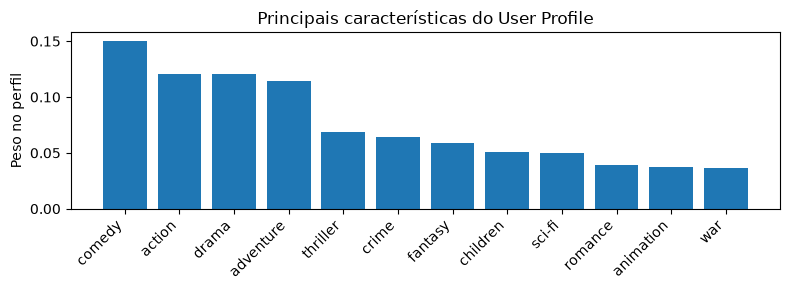

In [89]:
plot_user_profile(create_user_profile(user=1))

In [90]:
get_recommendations(modelo_rating, user=1, topN=5)

,movieId,title,genres,imdb_score
0,1218,"Killer, The (Die xue shuang xiong)",Action|Crime|Drama|Thriller,3.668102
1,6188,Old School,Comedy,3.465876
2,306,Three Colors: Red (Trois couleurs: Rouge),Drama,3.874481
3,6283,Cowboy Bebop: The Movie (Cowboy Bebop: Tengoku no Tobira),Action|Animation|Sci-Fi|Thriller,3.702139
4,2467,"Name of the Rose, The (Name der Rose, Der)",Crime|Drama|Mystery|Thriller,3.587483


In [91]:
predict(modelo_rating, userId=1, movieId=3508)

np.float32(5.0)

In [92]:
predict(modelo_rating, userId=1, movieId=2371)

np.float32(4.6319885)

In [93]:
predict(modelo_rating, userId=1, movieId=96610)

np.float32(5.0)

In [94]:
predict(modelo_rating, userId=1, movieId=955)

np.float32(4.202157)

In [95]:
predict(modelo_rating, userId=1, movieId=720)

np.float32(4.244446)

#### Usuário 3

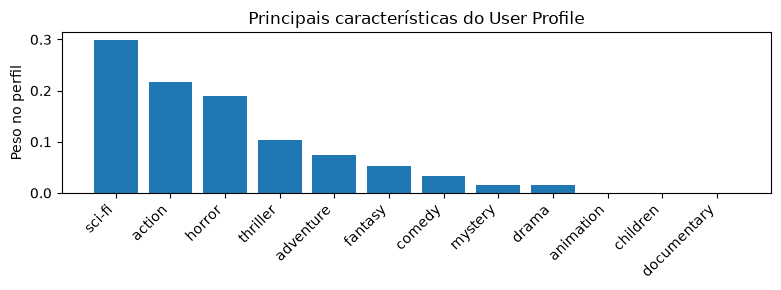

In [96]:
plot_user_profile(create_user_profile(user=3))

In [97]:
get_recommendations(modelo_rating, user=3, topN=5)

,movieId,title,genres,imdb_score
0,115713,Ex Machina,Drama|Sci-Fi|Thriller,3.753028
1,3444,Bloodsport,Action,3.103446
2,4232,Spy Kids,Action|Adventure|Children|Comedy,3.023298
3,5152,We Were Soldiers,Action|Drama|War,3.309705
4,3837,Phantasm II,Action|Fantasy|Horror|Sci-Fi|Thriller,3.071836


O usuário 3 tem as maiores preferências para os gêneros de ficção, Ação e Horror

Foi recomendado um filme dos gêneros Comedy|Drama|Romance e outro com Drama|Mystery|Thriller

#### Usuário 405

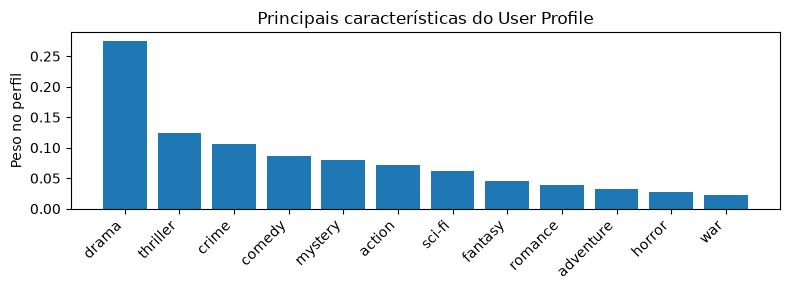

In [98]:
plot_user_profile(create_user_profile(user=405))

In [99]:
get_recommendations(modelo_rating, user=405, topN=5)

,movieId,title,genres,imdb_score
0,72,Kicking and Screaming,Comedy|Drama,3.241377
1,232,Eat Drink Man Woman (Yin shi nan nu),Comedy|Drama|Romance,3.646175
2,3567,Bossa Nova,Comedy|Drama|Romance,3.436203
3,170705,Band of Brothers,Action|Drama|War,3.710127
4,4235,Amores Perros (Love's a Bitch),Drama|Thriller,3.745689


O usuário 405 tem as maiores preferências para os gêneros de Drama, Thriller e Crime

Foi recomendado um filme dos gêneros Comedy|Drama|Romance e outro com Animation|Comedy


**Recomendações da abordagem baseada em modelo**

As recomendações baseadas em modelos podem proporcionar maior serendipidade, surpreendendo os usuários com sugestões inesperadas.

Filmes que aparentemente não seguem o padrão de preferências do usuário podem revelar-se relevantes, oferecendo oportunidades para descobrir conteúdos novos e interessantes.

Esta estratégia é altamente personalizada, por isso é possível recomendar filmes inesperados que tem alta probabilidade de surpreender.

# Recomendação baseada em modelo (*ranking*)

Existem outros tipos de métodos, cujo foco não é prever a nota exata, mas sim aprender uma ordem de preferência
𝑢 prefere o item 𝑖 ao item 𝑗. Estes métodos se adaptam melhor a cenários de e-commerce, streaming, música, etc.


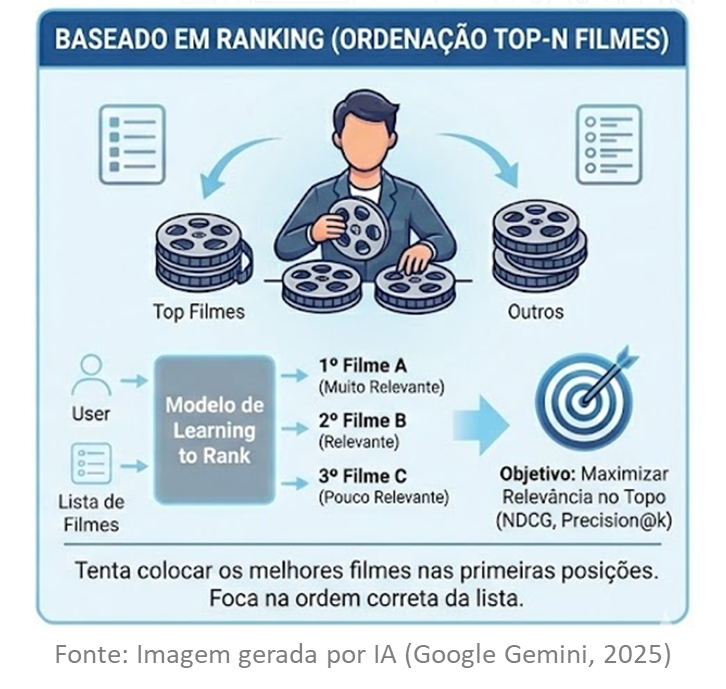

## Treinar modelo de *ranking*

Definir como interação positiva, notas acima da média do usuário para capturar o que é "bom" dentro da régua de cada indivíduo.



In [100]:
modelo_ranking = BPR(
    k=20,
    max_iter=500,
    learning_rate=0.01,
    lambda_reg=0.01,
    name="BPR"
)

modelo_ranking.fit(
    dataset
)

print("Modelo de ranking treinado.")

Modelo de ranking treinado.


## Predição com modelo baseado em *ranking*

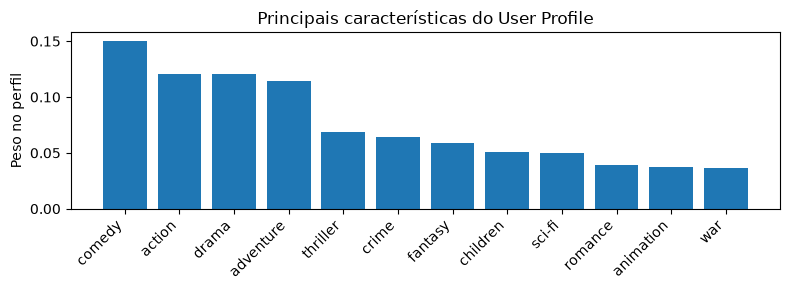

In [101]:
plot_user_profile(create_user_profile(user=1))

In [102]:
get_recommendations(modelo_ranking, user=1, topN=5)

,movieId,title,genres,imdb_score
0,3175,Galaxy Quest,Adventure|Comedy|Sci-Fi,3.545977
1,924,2001: A Space Odyssey,Adventure|Drama|Sci-Fi,3.846288
2,1200,Aliens,Action|Adventure|Horror|Sci-Fi,3.917497
3,1036,Die Hard,Action|Crime|Thriller,3.827026
4,2699,Arachnophobia,Comedy|Horror,2.876807


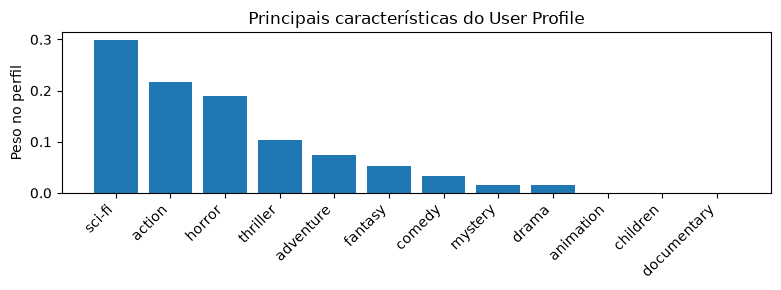

In [103]:
plot_user_profile(create_user_profile(user=3))

In [104]:
get_recommendations(modelo_ranking, user=3, topN=5)

,movieId,title,genres,imdb_score
0,1253,"Day the Earth Stood Still, The",Drama|Sci-Fi|Thriller,3.672413
1,1909,"X-Files: Fight the Future, The",Action|Crime|Mystery|Sci-Fi|Thriller,3.409059
2,1024,"Three Caballeros, The",Animation|Children|Musical,3.424136
3,2015,"Absent-Minded Professor, The",Children|Comedy|Fantasy,3.325669
4,2529,Planet of the Apes,Action|Drama|Sci-Fi,3.728647


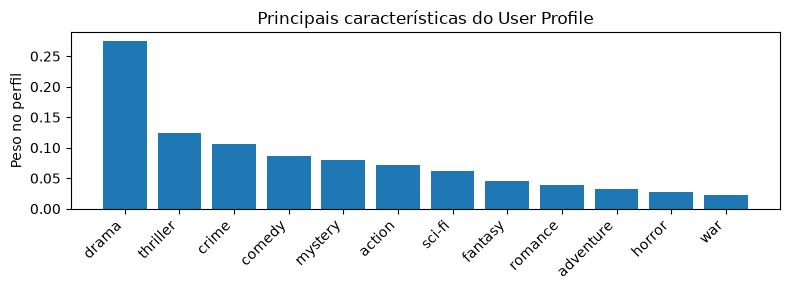

In [105]:
plot_user_profile(create_user_profile(user=405))

In [106]:
get_recommendations(modelo_ranking, user=405, topN=5)

,movieId,title,genres,imdb_score
0,6016,City of God (Cidade de Deus),Action|Adventure|Crime|Drama|Thriller,4.051929
1,6502,28 Days Later,Action|Horror|Sci-Fi,3.878538
2,6874,Kill Bill: Vol. 1,Action|Crime|Thriller,3.916872
3,1208,Apocalypse Now,Action|Drama|War,4.145362
4,778,Trainspotting,Comedy|Crime|Drama,3.976235


Estratégia de estimar a ordem formando o ranking

Não prediz a nota e sim um score pelo modelo BPR

Pq nessa abordagem retorna filmes de gêneros diferentes do perfil do usuário?

O modelo tenta encontrar para cada usuário a melhor ordem possível utilizando as avaliações conhecidas.

O modelo encontra os usuários que avaliaram os filmes de forma semelhantes/parecida. 

Porém o perfil desses usuários podem ser diferentes, por isso a serendipidade no resultado da ordenação. 

Perfis diferentes que avaliaram um conjunto de filmes da mesma forma ou forma semelhante. 

A estratégia de recomendação colaborativa tem essa capacidade de trazer novidades.


# Avaliação de modelos colaborativos

**Avaliação das predições**

Modelos de recomendação colaborativa procuram estimar a relevância das sugestões para um usuário

Existem dois tipos de modelos
* Baseados em rating, que estimam a avaliação de um usuário para um item
* Baseados em ranking, que estimam a ordem de relevância das sugestões

Independente do modelo, como saber se uma predição é boa?

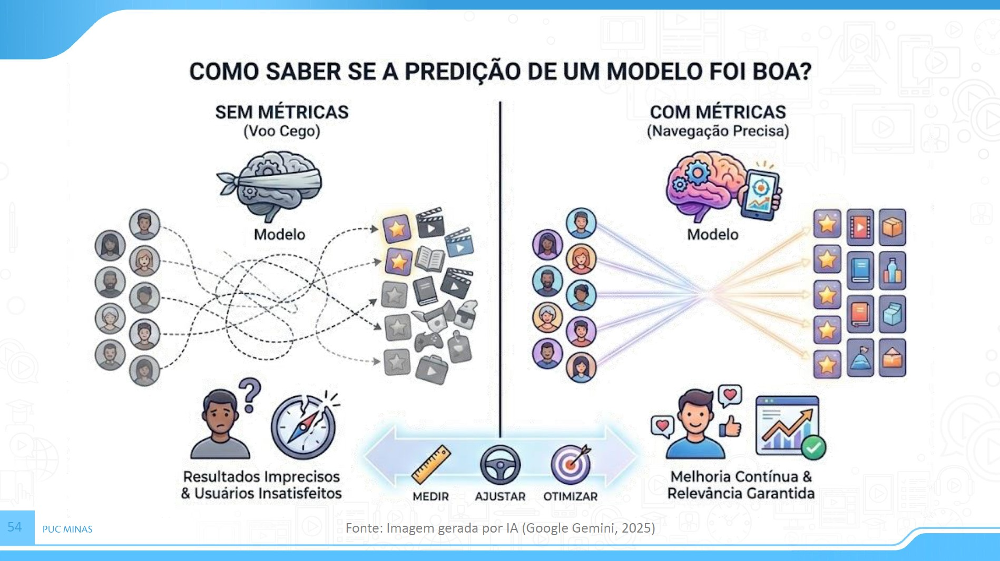

In [107]:
Image('./imagens/aula_05_021.jpg', width=1000)

## Métodos baseados em *rating*

Avaliação baseada em ratings

Para avaliação dos modelos de recomendação baseados em ratings, geralmente compara-se a predição do modelo com o valor real esperado (avaliação conhecida)

Nesta comparação, avalia-se alguma métrica baseada no erro
*  Diferença entre o valor da avaliação predita com a avaliação esperada
*  Ex: o modelo estimou avaliação 4.0 e a avaliação real esperada deveria ser 4.2

Métricas 
* Mean Absolut Erro (MAE)
* Root Mean Squared Error (RMSE)

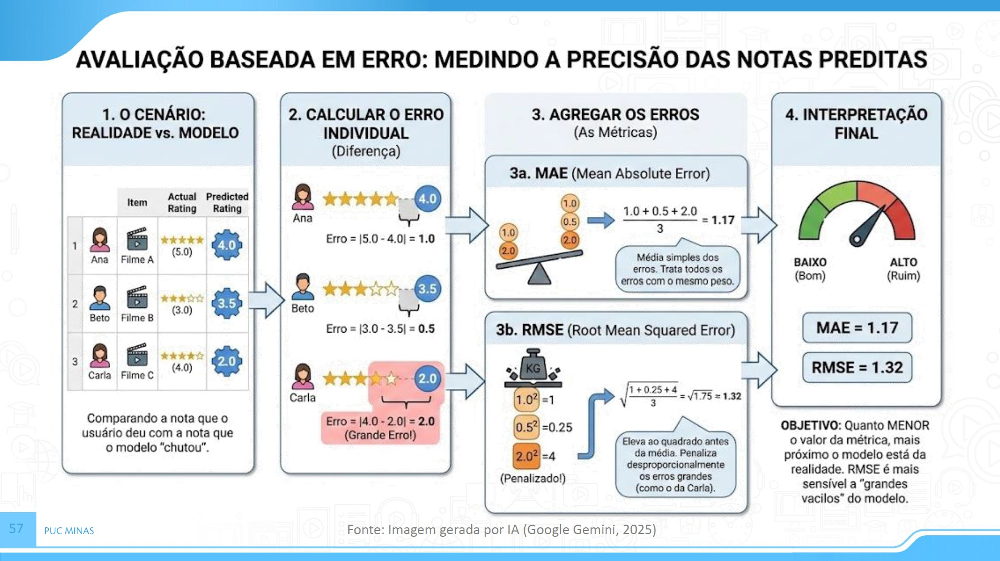

In [108]:
Image('./imagens/aula_05_022.jpg', width=1000)

### Biblioteca **`cornac`**

#### Separar os conjuntos de treino (80%) e teste (20%) para avaliação

In [109]:
eval_method = RatioSplit(
    data=data_cornac,
    test_size=0.20,
    seed=42,
    exclude_unknowns=True,
    verbose=False
)

#### Treinar diversos modelos colaborativos de *rating*

In [110]:
modelos = [

    UserKNN(
        k=20,
        similarity="pearson",
        name="Cornac - UserKNN"
    ),

    ItemKNN(
        k=20,
        similarity="pearson",
        name="Cornac - ItemKNN"
    ),

    MF(
        k=20,
        max_iter=500,
        learning_rate=0.01,
        lambda_reg=0.02,
        use_bias=True,
        seed=42,
        name="Cornac - MF"
    ),

    SVD(
        k=20,
        max_iter=500,
        learning_rate=0.01,
        lambda_reg=0.02,
        seed=42,
        name="Cornac - SVD"
    ),

    NMF(
        k=20,
        max_iter=500,
        seed=42,
        name="Cornac - NMF"
    ),

    PMF(
        k=20,
        max_iter=50,
        seed=42,
        name="Cornac - PMF"
    )
]

print('Modelos configurados')

Modelos configurados


In [111]:
resultados = []

for modelo in modelos:

    resultado, _ = eval_method.evaluate(
        model=modelo,
        metrics=[
            RMSE(),
            MAE()
        ],
        user_based=True
    )

    resultados.append({
        "modelo": modelo,
        "nome": modelo.name,
        "RMSE": resultado.metric_avg_results["RMSE"],
        "MAE": resultado.metric_avg_results["MAE"]
    })

resultados

  0%|          | 0/610 [00:00<?, ?it/s]

  0%|          | 0/8928 [00:00<?, ?it/s]

[{'modelo': <cornac.models.knn.recom_knn.UserKNN at 0x108a08aa660>,
  'nome': 'Cornac - UserKNN',
  'RMSE': 0.8856328417782878,
  'MAE': 0.7153355268808681},
 {'modelo': <cornac.models.knn.recom_knn.ItemKNN at 0x108c0b3bb60>,
  'nome': 'Cornac - ItemKNN',
  'RMSE': 0.930727097548865,
  'MAE': 0.7638243913869286},
 {'modelo': <cornac.models.mf.recom_mf.MF at 0x10809bd5df0>,
  'nome': 'Cornac - MF',
  'RMSE': 0.9765746569489251,
  'MAE': 0.7895592316422464},
 {'modelo': <cornac.models.svd.recom_svd.SVD at 0x108a0832b40>,
  'nome': 'Cornac - SVD',
  'RMSE': 0.9765746569489251,
  'MAE': 0.7895592316422464},
 {'modelo': <cornac.models.nmf.recom_nmf.NMF at 0x108a081a240>,
  'nome': 'Cornac - NMF',
  'RMSE': 0.9298492503549296,
  'MAE': 0.7615700305307437},
 {'modelo': <cornac.models.pmf.recom_pmf.PMF at 0x1085f1776e0>,
  'nome': 'Cornac - PMF',
  'RMSE': 0.8665461126318241,
  'MAE': 0.7100844950822581}]

### Comparação entre as abordagens colaborativas

In [112]:
df_cornac = pd.DataFrame(
    [
        {
            "Algoritmo": r["nome"],
            "RMSE": r["RMSE"],
            "MAE": r["MAE"],
            "Modelo": r["modelo"]
        }
        for r in resultados
    ]
)

df_cornac.sort_values("RMSE")

,Algoritmo,RMSE,MAE,Modelo
5,Cornac - PMF,0.866546,0.710084,<cornac.models.pmf.recom_pmf.PMF object at 0x000001085F1776E0>
0,Cornac - UserKNN,0.885633,0.715336,<cornac.models.knn.recom_knn.UserKNN object at 0x00000108A08AA660>
4,Cornac - NMF,0.929849,0.761570,<cornac.models.nmf.recom_nmf.NMF object at 0x00000108A081A240>
1,Cornac - ItemKNN,0.930727,0.763824,<cornac.models.knn.recom_knn.ItemKNN object at 0x00000108C0B3BB60>
3,Cornac - SVD,0.976575,0.789559,<cornac.models.svd.recom_svd.SVD object at 0x00000108A0832B40>
2,Cornac - MF,0.976575,0.789559,<cornac.models.mf.recom_mf.MF object at 0x0000010809BD5DF0>


### Biblioteca **`surprise`**

#### Separar os conjuntos de treino (80%) e teste (20%) para avaliação

In [113]:
reader = Reader(
    rating_scale=(0.0, 5.0)
)

data_surprise = surprise.Dataset.load_from_df(
    ratings[
        ["userId", "movieId", "rating"]
    ],
    reader
)

trainset_surprise, testset_surprise = train_test_split(
    data_surprise,
    test_size=0.20,
    random_state=42
)

#### Treinar diversos modelos colaborativos de *rating*

In [114]:
modelos_surprise = [

    KNNBasic(
        k=20,
        sim_options={
            "name": "pearson",
            "user_based": True
        },
        verbose=False
    ),

    KNNWithMeans(
        k=20,
        sim_options={
            "name": "pearson",
            "user_based": True
        },
        verbose=False
    ),

    KNNBaseline(
        k=20,
        sim_options={
            "name": "pearson_baseline",
            "user_based": True
        },
        verbose=False
    ),

    KNNBaseline(
        k=20,
        sim_options={
            "name": "pearson_baseline",
            "user_based": False
        },
        verbose=False
    ),

    surprise.SVD(
        n_factors=20,
        n_epochs=20,
        random_state=42
    ),

    SVDpp(
        n_factors=20,
        n_epochs=20,
        random_state=42
    ),

    surprise.NMF(
        n_factors=20,
        n_epochs=50,
        random_state=42
    ),

    BaselineOnly(
        verbose=False
    )
]

print('Modelos configurados')

Modelos configurados


In [115]:
nomes_surprise = [
    "Surprise - UserKNN",
    "Surprise - UserKNNWithMeans",
    "Surprise - UserKNNBaseline",
    "Surprise - ItemKNNBaseline",
    "Surprise - SVD",
    "Surprise - SVD++",
    "Surprise - NMF",
    "Surprise - BaselineOnly"
]

In [116]:
resultados_surprise = []

for nome, modelo in zip(
    nomes_surprise,
    modelos_surprise
):

    print(f'Treinando modelo {nome}')
    modelo.fit(
        trainset_surprise
    )

    predicoes = modelo.test(
        testset_surprise
    )

    rmse = accuracy.rmse(
        predicoes,
        verbose=False
    )

    mae = accuracy.mae(
        predicoes,
        verbose=False
    )

    resultados_surprise.append({
        "modelo": modelo,
        "nome": nome,
        "RMSE": rmse,
        "MAE": mae
    })

Treinando modelo Surprise - UserKNN
Treinando modelo Surprise - UserKNNWithMeans
Treinando modelo Surprise - UserKNNBaseline
Treinando modelo Surprise - ItemKNNBaseline
Treinando modelo Surprise - SVD
Treinando modelo Surprise - SVD++
Treinando modelo Surprise - NMF
Treinando modelo Surprise - BaselineOnly


### Comparação entre as abordagens colaborativas

In [117]:
df_surprise = pd.DataFrame(
    [
        {
            "Algoritmo": r["nome"],
            "RMSE": r["RMSE"],
            "MAE": r["MAE"],
            "Modelo": r["modelo"]
        }
        for r in resultados_surprise
    ]
)

df_surprise.sort_values(
    "RMSE"
)

,Algoritmo,RMSE,MAE,Modelo
3,Surprise - ItemKNNBaseline,0.863157,0.656500,<surprise.prediction_algorithms.knns.KNNBaseline object at 0x00000108A08A9820>
5,Surprise - SVD++,0.869522,0.666119,<surprise.prediction_algorithms.matrix_factorization.SVDpp object at 0x00000108C4A6F890>
4,Surprise - SVD,0.878010,0.675098,<surprise.prediction_algorithms.matrix_factorization.SVD object at 0x00000108C0B3B710>
7,Surprise - BaselineOnly,0.878510,0.677786,<surprise.prediction_algorithms.baseline_only.BaselineOnly object at 0x00000108A08A9160>
2,Surprise - UserKNNBaseline,0.887066,0.672751,<surprise.prediction_algorithms.knns.KNNBaseline object at 0x00000108A08AABD0>
1,Surprise - UserKNNWithMeans,0.906207,0.689904,<surprise.prediction_algorithms.knns.KNNWithMeans object at 0x00000108A08A80E0>
6,Surprise - NMF,0.929045,0.703827,<surprise.prediction_algorithms.matrix_factorization.NMF object at 0x00000108A08ABE90>
0,Surprise - UserKNN,0.985782,0.760060,<surprise.prediction_algorithms.knns.KNNBasic object at 0x00000108A08A8830>


## Descobrindo o melhor modelo

### Comparação dos resultados

In [118]:
df_comparacao = pd.concat(
    [
        df_cornac,
        df_surprise
    ],
    ignore_index=True
)

df_comparacao = (
    df_comparacao
    .sort_values("RMSE")
    .reset_index(drop=True)
)

df_comparacao

,Algoritmo,RMSE,MAE,Modelo
0,Surprise - ItemKNNBaseline,0.863157,0.656500,<surprise.prediction_algorithms.knns.KNNBaseline object at 0x00000108A08A9820>
1,Cornac - PMF,0.866546,0.710084,<cornac.models.pmf.recom_pmf.PMF object at 0x000001085F1776E0>
2,Surprise - SVD++,0.869522,0.666119,<surprise.prediction_algorithms.matrix_factorization.SVDpp object at 0x00000108C4A6F890>
3,Surprise - SVD,0.878010,0.675098,<surprise.prediction_algorithms.matrix_factorization.SVD object at 0x00000108C0B3B710>
4,Surprise - BaselineOnly,0.878510,0.677786,<surprise.prediction_algorithms.baseline_only.BaselineOnly object at 0x00000108A08A9160>
5,Cornac - UserKNN,0.885633,0.715336,<cornac.models.knn.recom_knn.UserKNN object at 0x00000108A08AA660>
6,Surprise - UserKNNBaseline,0.887066,0.672751,<surprise.prediction_algorithms.knns.KNNBaseline object at 0x00000108A08AABD0>
7,Surprise - UserKNNWithMeans,0.906207,0.689904,<surprise.prediction_algorithms.knns.KNNWithMeans object at 0x00000108A08A80E0>
8,Surprise - NMF,0.929045,0.703827,<surprise.prediction_algorithms.matrix_factorization.NMF object at 0x00000108A08ABE90>
9,Cornac - NMF,0.929849,0.761570,<cornac.models.nmf.recom_nmf.NMF object at 0x00000108A081A240>


In [119]:
melhor = df_comparacao.iloc[0]

best_rat = melhor["Modelo"]

print("Melhor modelo:", melhor["Algoritmo"])
print("RMSE:", melhor["RMSE"])
print("MAE:", melhor["MAE"])

Melhor modelo: Surprise - ItemKNNBaseline
RMSE: 0.8631565681180605
MAE: 0.6565004861195455


### Realizando recomendações

In [120]:
def recomendar_itens_surprise(modelo, userId, top_n=10):

    # Itens já avaliados pelo usuário
    vistos = set(
        ratings.loc[
            ratings["userId"] == userId,
            "movieId"
        ]
    )

    # Itens candidatos
    candidatos = [
        movieId
        for movieId in movies.index
        if movieId not in vistos
    ]

    # Predição para cada item candidato
    predicoes = []

    for movieId in candidatos:

        predicao = modelo.predict(
            uid=userId,
            iid=movieId
        )

        predicoes.append(
            (
                movieId,
                predicao.est
            )
        )

    # Ordena pela nota prevista
    predicoes.sort(
        key=lambda x: x[1],
        reverse=True
    )

    # Retorna somente os IDs
    recomendacoes = [
        movieId
        for movieId, score
        in predicoes[:top_n]
    ]

    return recomendacoes

recomendar_itens_surprise(best_rat, userId=1)

[318, 670, 4079, 4154, 4294, 6732, 8610, 313, 1276, 58559]

In [121]:
def get_recommendations_surprise(model, user, topN=10):
    recs = recomendar_itens_surprise(model, userId=user, top_n=topN)
    # Exibir recomendações
    df_recs = pd.DataFrame(recs, columns=['movieId'])
    colunas = ['movieId', 'title', 'genres', 'imdb_score']
    return df_recs.join(movies, on='movieId')[colunas]

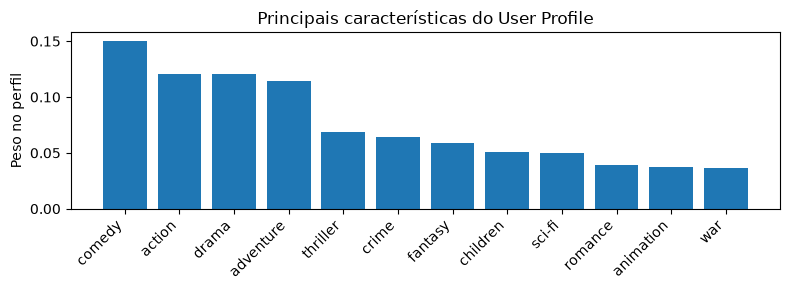

In [122]:
plot_user_profile(create_user_profile(user=1))

In [123]:
get_recommendations_surprise(best_rat, user=1, topN=5)

,movieId,title,genres,imdb_score
0,318,"Shawshank Redemption, The",Crime|Drama,4.396816
1,670,"World of Apu, The (Apur Sansar)",Drama,3.532912
2,4079,Amazon Women on the Moon,Comedy|Sci-Fi,3.442003
3,4154,Recess: School's Out,Animation|Children,3.396549
4,4294,"5,000 Fingers of Dr. T, The",Children|Fantasy|Musical,3.396549


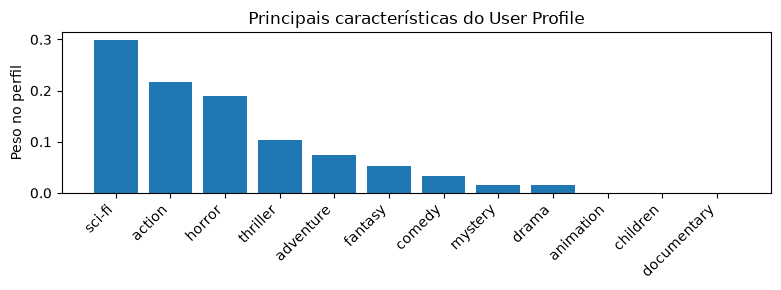

In [124]:
plot_user_profile(create_user_profile(user=3))

In [125]:
get_recommendations_surprise(best_rat, user=3, topN=5)

,movieId,title,genres,imdb_score
0,330,Tales from the Hood,Action|Crime|Horror,3.157469
1,505,North,Comedy,2.803877
2,577,Andre,Adventure|Children|Drama,2.912464
3,634,Theodore Rex,Comedy,2.950926
4,656,Eddie,Comedy,3.168717


## Métodos baseados em *ranking*

**Avaliação baseada em ranking**

Avaliar a qualidade de um ranking consiste em associar uma métrica quantitativa a uma lista ordenada de sugestões
* A métrica deve ser diretamente associada a relevância dos resultados para o usuário

Para avaliar a qualidade das recomendações deve ser medido o quão bem o ranking atende à necessidade de informação dos usuários, de acordo com a relevância estimada

**Métricas de avaliação**
* Precision
* Recall
* Normalized Discounted Cumulative Gain (NDCG)
* Mean Average Precision (MAP)

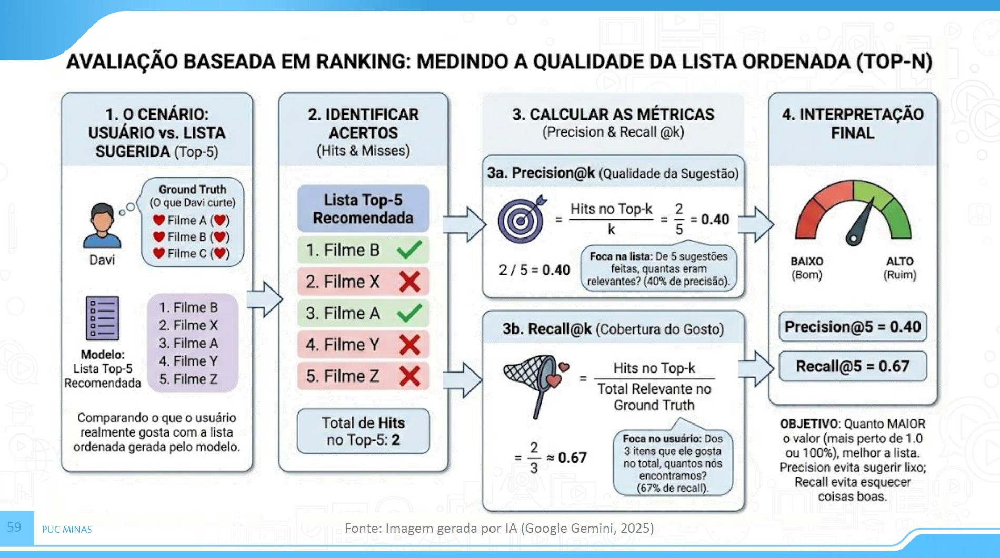

In [126]:
Image('./imagens/aula_05_023.jpg', width=1000)

### Separar os conjuntos de treino (80%) e teste (20%) para avaliação

**Threshold - Limiar de relevância**

No sistema de ranking desse projeto foi considerada como uma nota relevante todas as notas iguais ou superiores a 4.0. 

Esse limiar é um padrão para datasets de filmes e livros com classificação como "Gostou" e representa sentimento positivo.

Convém mencionar que a definição do threshold impacta nas métricas de avaliação do ranking tais como AP, MAP, NDCG, Precision@K

Um sistema pode ter MAP alto com limiar ≥ 3 e MAP baixo com limiar = 5. 

In [127]:
eval_rank = RatioSplit(
    data=data_cornac,
    test_size=0.20,
    rating_threshold=4.0,
    seed=42,
    exclude_unknowns=True,
    verbose=False
)

### Treinar diversos modelos colaborativos de *rating*

In [128]:
modelos_ranking = [

    BPR(
        k=20,
        max_iter=500,
        learning_rate=0.01,
        lambda_reg=0.01,
        seed=42,
        name="BPR",
        verbose=True
    ),

    WBPR(
        k=20,
        max_iter=500,
        learning_rate=0.01,
        lambda_reg=0.01,
        seed=42,
        name="WBPR",
        verbose=True
    ),

]

#### Métricas

<font color = 'blue'>**Precision@K**</font>

A fórmula geral para Precision@K é:

$$
\text{Precision@K} = \frac{\text{Número de itens relevantes nos primeiros } K}{K}
$$

Para $K = 10$:

$$
\text{Precision@10} = \frac{\text{Número de itens relevantes nos primeiros 10}}{10}
$$

**Interpretação:** O resultado é um valor entre 0 e 1 (ou 0% a 100%). Um valor de 0.7 significa que 70% dos itens recomendados no top-10 eram relevantes.

<font color = 'blue'>**Recall@K**</font>

A fórmula geral para Recall@K é:

$$
\text{Recall@K} = \frac{\text{Número de itens relevantes nos primeiros } K}{\text{Número total de itens relevantes}}
$$

Para $K = 10$:

$$
\text{Recall@10} = \frac{\text{Número de itens relevantes nos primeiros 10}}{\text{Número total de itens relevantes}}
$$

**Interpretação:** O resultado é um valor entre 0 e 1 (ou 0% a 100%). Um valor de 0.6 significa que 60% de todos os itens relevantes foram recuperados nas primeiras 10 recomendações.

<font color = 'blue'>**Average Precision (AP)**</font>

A fórmula é:

$$
AP = \frac{1}{R} \sum_{k=1}^{n} P(k) \times \mathrm{rel}(k)
$$

**Onde:**

- $R$ = número total de itens relevantes no conjunto de teste (ground truth)
- $n$ = número de itens recomendados (tamanho da lista)
- $P(k)$ = Precisão nos primeiros $k$ itens (itens relevantes / $k$)
- $\mathrm{rel}(k)$ = 1 se o item na posição $k$ é relevante, 0 caso contrário



<font color = 'blue'>**Mean Average Precision (MAP)**</font>

Quando você tem muitos usuários, calcula-se a AP para cada um e tira-se a média:

$$
MAP = \frac{1}{U} \sum_{u=1}^{U} AP_u
$$

**Onde:**

- $U$ = número de usuários
- $AP_u$ = Average Precision do usuário $u$

O MAP é a métrica agregada mais usada em sistemas de recomendação e recuperação de informação.

<font color = 'blue'>**NDCG@K**</font>

**1. DCG (Discounted Cumulative Gain):**

$$
DCG@K = \sum_{k=1}^{K} \frac{rel(k)}{\log_2(k+1)}
$$

**2. IDCG (Ideal DCG):**

$$
IDCG@K = \sum_{k=1}^{K} \frac{rel^*(k)}{\log_2(k+1)}
$$

onde $rel^*(k)$ são os itens relevantes na ordem ideal (melhor ordenação possível).

**3. NDCG@K (Normalized DCG):**

$$
NDCG@K = \frac{DCG@K}{IDCG@K}
$$

Para $K = 10$:

$$
NDCG@10 = \frac{DCG@10}{IDCG@10}
$$

**Onde:**

- $rel(k)$ = relevância do item na posição $k$ (ex: 1 se relevante, 0 caso contrário)
- $K$ = número de itens recomendados (neste caso, 10)
- O denominador $\log_2(k+1)$ aplica um desconto (discount) a posições mais baixas

**Interpretação:** O resultado varia entre 0 e 1. Valores próximos de 1 indicam que os itens relevantes foram colocados nas primeiras posições (melhor ordenação). O NDCG é especialmente útil quando há diferentes níveis de relevância e quando a posição do item na lista importa.

In [129]:
resultados_ranking = []

for modelo in modelos_ranking:

    resultado, _ = eval_rank.evaluate(
        model=modelo,
        metrics=[
            Precision(k=10),
            Recall(k=10),
            NDCG(k=10),
            MAP()
        ],
        user_based=True
    )

    resultados_ranking.append({
        "modelo": modelo,
        "nome": modelo.name,
        "Precision@10": resultado.metric_avg_results["Precision@10"],
        "Recall@10": resultado.metric_avg_results["Recall@10"],
        "NDCG@10": resultado.metric_avg_results["NDCG@10"],
        "MAP": resultado.metric_avg_results["MAP"]
    })

resultados_ranking

  0%|          | 0/500 [00:00<?, ?it/s]

Optimization finished!


  0%|          | 0/500 [00:00<?, ?it/s]

Optimization finished!


[{'modelo': <cornac.models.bpr.recom_bpr.BPR at 0x108c489ba70>,
  'nome': 'BPR',
  'Precision@10': np.float64(0.10521008403361386),
  'Recall@10': np.float64(0.10669539376433862),
  'NDCG@10': np.float64(0.13474882741728791),
  'MAP': np.float32(0.10088974)},
 {'modelo': <cornac.models.bpr.recom_wbpr.WBPR at 0x108a07ed400>,
  'nome': 'WBPR',
  'Precision@10': np.float64(0.05512605042016824),
  'Recall@10': np.float64(0.06612452651907408),
  'NDCG@10': np.float64(0.07059319383323946),
  'MAP': np.float32(0.057960037)}]

### Comparação entre as abordagens colaborativas

In [130]:
df_resultados_ranking = pd.DataFrame(
    [
        {
            "Modelo": r["nome"],
            "Precision@10": r["Precision@10"],
            "Recall@10": r["Recall@10"],
            "NDCG@10": r["NDCG@10"],
            "MAP": r["MAP"]
        }
        for r in resultados_ranking
    ]
)

df_resultados_ranking.sort_values(
    "NDCG@10",
    ascending=False
)

,Modelo,Precision@10,Recall@10,NDCG@10,MAP
0,BPR,0.105210,0.106695,0.134749,0.10089
1,WBPR,0.055126,0.066125,0.070593,0.05796


In [131]:
melhor = max(
    resultados_ranking,
    key=lambda x: x["NDCG@10"]
)

best_rank = melhor["modelo"]

print("Melhor modelo:", melhor["nome"])
print("NDCG@10:", melhor["NDCG@10"])
print("Precision@10:", melhor["Precision@10"])
print("Recall@10:", melhor["Recall@10"])
print("MAP:", melhor["MAP"])

Melhor modelo: BPR
NDCG@10: 0.13474882741728791
Precision@10: 0.10521008403361386
Recall@10: 0.10669539376433862
MAP: 0.10088974


### Realizando recomendações

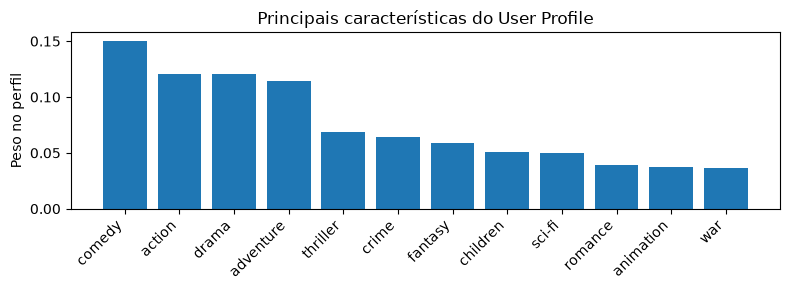

In [132]:
plot_user_profile(create_user_profile(user=1))

In [133]:
get_recommendations(best_rank, user=1, topN=5)

,movieId,title,genres,imdb_score
0,1391,Mars Attacks!,Action|Comedy|Sci-Fi,3.109074
1,1200,Aliens,Action|Adventure|Horror|Sci-Fi,3.917497
2,1544,"Lost World: Jurassic Park, The",Action|Adventure|Sci-Fi|Thriller,2.813974
3,1387,Jaws,Action|Horror,3.938620
4,2355,"Bug's Life, A",Adventure|Animation|Children|Comedy,3.493684


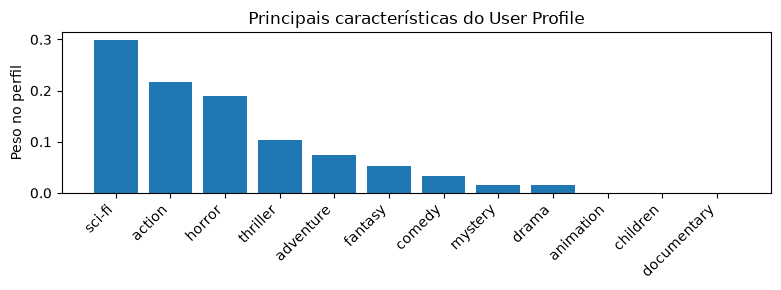

In [134]:
plot_user_profile(create_user_profile(user=3))

In [135]:
get_recommendations(best_rank, user=3, topN=5)

,movieId,title,genres,imdb_score
0,2792,Airplane II: The Sequel,Comedy,3.209358
1,1375,Star Trek III: The Search for Spock,Action|Adventure|Sci-Fi,3.262001
2,1231,"Right Stuff, The",Drama,3.689098
3,1374,Star Trek II: The Wrath of Khan,Action|Adventure|Sci-Fi|Thriller,3.702282
4,2366,King Kong,Action|Adventure|Fantasy|Horror,3.540060
